# Notebook 04 — ClinicalBERT Frozen-Encoder Baseline

This notebook trains and evaluates a **non-fine-tuned ClinicalBERT baseline** for depression detection. The pretrained ClinicalBERT encoder is frozen, and only the randomly initialised binary classification head is trained.

It follows the experimental decisions established in Notebooks 01–03:

- use only the **masked** depression dataset;
- use `text_selected` because ClinicalBERT has a 512-token input limit;
- preserve the existing patient-level `train`, `validation`, and `test` assignments;
- perform model-specific tokenisation here, not in the cohort-building notebooks;
- use class weights calculated from the training split only;
- select the best checkpoint and classification threshold using validation data only;
- evaluate the test split only after the model and threshold have been fixed.

## Baseline training strategy

Each selected discharge note is treated as one classification example and truncated to 512 tokens when necessary. This notebook does **not** chunk notes. All pretrained ClinicalBERT embeddings, Transformer encoder layers, and pooler parameters remain frozen. Only the classification head is updated.

This design provides a controlled frozen-feature baseline for comparison with the fully fine-tuned ClinicalBERT experiment. The notebook verifies that every encoder tensor remains unchanged while the classification head changes.

> Run the notebook first with `SMOKE_TEST = True`. After the complete pipeline succeeds, change it to `False` for the full experiment.

The notebook preserves the same reporting structure as the fine-tuned version: token-length audits, representative split examples, model construction tables, live training progress, learning curves, validation threshold selection, test metrics, 100 test predictions, confusion matrix, ROC and PR curves, deployment bundle, and run manifest.


## 1. Environment and dependencies

Install the required libraries once in the active Python environment if they are not already available:

```bash
pip install torch transformers datasets accelerate scikit-learn pyarrow pandas matplotlib seaborn tqdm
```

After installing or upgrading packages, restart the Jupyter kernel before running the notebook from the beginning.

In [1]:
# ============================================================
# CELL 1 - IMPORT LIBRARIES
# ============================================================

from pathlib import Path
import gc
import hashlib
import html
import json
import math
import random
import time
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn.functional as F

from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader

import datasets as hf_datasets

from datasets import Dataset, DatasetDict

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import transformers

from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

from tqdm.auto import tqdm

from IPython.display import display, HTML

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")
print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("Datasets version:", hf_datasets.__version__)

PyTorch version: 2.13.0
Transformers version: 5.15.1
Datasets version: 5.0.1


In [2]:
# ============================================================
# CELL 2 - SET RANDOM SEEDS AND SELECT DEVICE
# ============================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Random seed:", SEED)
print("Selected device:", DEVICE)

Random seed: 42
Selected device: mps


## 2. Experiment configuration

The main settings are deliberately kept in one cell.

To run the other task, change only:

```python
TASK_NAME = "anxiety"
```

The notebook automatically selects the corresponding masked dataset and gives the outputs a task-specific name.

In [3]:
# ============================================================
# CELL 3 - LOCATE THE PROJECT ROOT
# ============================================================

def find_project_root(starting_path):
    starting_path = Path(starting_path).expanduser().resolve()
    for location in [starting_path, *starting_path.parents]:
        if (location / ".git").exists() or (location / "dataset").exists():
            return location

    raise FileNotFoundError(
        "Could not locate the project root. " "Open Jupyter from inside the project repository."
    )

PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_DIR = PROJECT_ROOT / "dataset"
print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATASET_DIR)

Project root: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection
Dataset directory: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset


In [4]:
# ============================================================
# CELL 4 - CONFIGURE THE FROZEN-ENCODER BASELINE
# ============================================================

# This notebook is the depression frozen-encoder baseline.
TASK_NAME = "depression"

# Notebook 03 writes the full prepared files to model_datasets.
# Use model_datasets_smoke only when intentionally testing the
# small output produced by Notebook 03's smoke-test mode.
MODEL_DATASET_FOLDER = "model_datasets"
MODEL_NAME = "emilyalsentzer/Bio_ClinicalBERT"
TRAINING_STRATEGY = "frozen_encoder_classifier_only"
TEXT_COLUMN = "text_selected"
MAX_LENGTH = 512

# Start with True. Change to False only after the smoke run passes.
SMOKE_TEST = True
SMOKE_SPLIT_SIZES = {"train": 20, "validation": 25, "test": 25}

# The smoke test evaluates its small test subset to verify that the
# full pipeline works. During the final experiment, inspect test
# results only once after all decisions have been frozen.
EVALUATE_TEST_SET = True
NUMBER_OF_EPOCHS = 1 if SMOKE_TEST else 8
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_PROPORTION = 0.10
MAX_GRADIENT_NORM = 1.0
# Validation PR-AUC is monitored because the positive class is imbalanced.
EARLY_STOPPING_PATIENCE = 2
EARLY_STOPPING_MINIMUM_IMPROVEMENT = 1e-4

# False means every requested epoch runs. The first patience-trigger epoch
# is still recorded and saved as a separate diagnostic checkpoint.
STOP_TRAINING_WHEN_PATIENCE_REACHED = False
SAVE_EARLY_STOP_SIGNAL_MODEL = True
EXAMPLE_RECORDS_PER_SPLIT = 5
PREDICTION_DISPLAY_COUNT = 100
REPORT_FIGURE_DPI = 300
if DEVICE.type == "cuda":
    # Recommended starting point for one NVIDIA T4 with 16 GB VRAM.
    TRAIN_BATCH_SIZE = 8
    EVALUATION_BATCH_SIZE = 16
    GRADIENT_ACCUMULATION_STEPS = 2
    USE_MIXED_PRECISION = True
elif DEVICE.type == "mps":
    TRAIN_BATCH_SIZE = 2
    EVALUATION_BATCH_SIZE = 4
    GRADIENT_ACCUMULATION_STEPS = 8
    USE_MIXED_PRECISION = False
else:
    TRAIN_BATCH_SIZE = 2
    EVALUATION_BATCH_SIZE = 2
    GRADIENT_ACCUMULATION_STEPS = 8
    USE_MIXED_PRECISION = False

if TASK_NAME not in {"depression", "anxiety"}:
    raise ValueError("TASK_NAME must be either " "'depression' or 'anxiety'.")

MODEL_DATASET_DIR = DATASET_DIR / MODEL_DATASET_FOLDER
DATASET_PATHS = {
    "depression": (MODEL_DATASET_DIR / "depression_dataset_masked.parquet"),
    "anxiety": (MODEL_DATASET_DIR / "anxiety_dataset_masked.parquet"),
}
DATASET_PATH = DATASET_PATHS[TASK_NAME]
RUN_MODE = "smoke" if SMOKE_TEST else "full"
RUN_NAME = f"clinicalbert_frozen_baseline_{TASK_NAME}_" f"masked_selected_{RUN_MODE}"
OUTPUT_DIR = PROJECT_ROOT / "model_outputs" / "clinicalbert_frozen_baseline" / RUN_NAME
BEST_MODEL_DIR = OUTPUT_DIR / "best_model"
EARLY_STOP_SIGNAL_MODEL_DIR = OUTPUT_DIR / "early_stop_signal_model"
FINAL_EPOCH_MODEL_DIR = OUTPUT_DIR / "final_epoch_model"
DEPLOYMENT_BUNDLE_DIR = OUTPUT_DIR / "deployment_bundle"
DEPLOYMENT_MODEL_DIR = DEPLOYMENT_BUNDLE_DIR / "model"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
FIGURE_DIR = OUTPUT_DIR / "figures"
if os.name == "nt":
    MODEL_CACHE_DIR = Path(
        r"C:\hf_cache"
    )
else:
    MODEL_CACHE_DIR = (
        PROJECT_ROOT
        / "model_cache"
        / "huggingface_models"
    )
for directory in [
    OUTPUT_DIR,
    BEST_MODEL_DIR,
    EARLY_STOP_SIGNAL_MODEL_DIR,
    FINAL_EPOCH_MODEL_DIR,
    DEPLOYMENT_MODEL_DIR,
    PREDICTION_DIR,
    FIGURE_DIR,
    MODEL_CACHE_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

configuration_table = pd.DataFrame(
    {
        "setting": [
            "Task",
            "Dataset",
            "Text field",
            "Model",
            "Training strategy",
            "Maximum tokens",
            "Run mode",
            "Maximum epochs",
            "Stop when patience is reached",
            "Early-stopping patience",
            "Minimum PR-AUC improvement",
            "Device",
            "Training batch size",
            "Gradient accumulation",
            "Effective batch size",
            "Evaluation batch size",
            "Learning rate",
            "Output directory",
        ],
        "value": [
            TASK_NAME,
            str(DATASET_PATH),
            TEXT_COLUMN,
            MODEL_NAME,
            TRAINING_STRATEGY,
            MAX_LENGTH,
            RUN_MODE,
            NUMBER_OF_EPOCHS,
            STOP_TRAINING_WHEN_PATIENCE_REACHED,
            EARLY_STOPPING_PATIENCE,
            EARLY_STOPPING_MINIMUM_IMPROVEMENT,
            str(DEVICE),
            TRAIN_BATCH_SIZE,
            GRADIENT_ACCUMULATION_STEPS,
            (TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS),
            EVALUATION_BATCH_SIZE,
            LEARNING_RATE,
            str(OUTPUT_DIR),
        ],
    }
)
display(configuration_table)

,setting,value
0,Task,depression
1,Dataset,/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/dataset/m...
2,Text field,text_selected
3,Model,emilyalsentzer/Bio_ClinicalBERT
4,Training strategy,frozen_encoder_classifier_only
5,Maximum tokens,512
6,Run mode,smoke
7,Maximum epochs,1
8,Stop when patience is reached,False
9,Early-stopping patience,2


## 3. Load and validate the masked task dataset

Only the columns required for modelling and traceability are loaded. No text cleaning, masking, section extraction, or split creation is repeated here.

In [5]:
# ============================================================
# CELL 5 - LOAD THE SELECTED MASKED DATASET
# ============================================================

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}\n"
        "Run Notebook 03 first, or check "
        "MODEL_DATASET_FOLDER in Cell 4."
    )

REQUIRED_COLUMNS = ["subject_id", "hadm_id", "split", "label", TEXT_COLUMN]
model_data = pd.read_parquet(DATASET_PATH, columns=REQUIRED_COLUMNS)
model_data = model_data.rename(columns={TEXT_COLUMN: "model_text"})
model_data["split"] = (
    model_data["split"].astype(str).str.strip().str.lower().replace({"val": "validation"})
)
model_data["label"] = model_data["label"].astype(int)
print("Loaded dataset:", DATASET_PATH.name)
print("Rows:", f"{len(model_data):,}")
print("Columns:", model_data.columns.tolist())
display(model_data.head())

Loaded dataset: depression_dataset_masked.parquet
Rows: 180,246
Columns: ['subject_id', 'hadm_id', 'split', 'label', 'model_text']


,subject_id,hadm_id,split,label,model_text
0,10000084,23052089,train,0,past medical history: [DEID] disease\n[DEID] Body Dementia \ndyslipidemia \nprostate cancer (s/p prostatectomy)\n\nc...
1,10000764,27897940,train,0,past medical history: MI after AAA repair when he was [DEID] y/o\nHTN\nHypercholesterolemia\n\nchief complaint: Epis...
2,10000980,29654838,test,0,"past medical history: 1. CAD RISK FACTORS: +Diabetes, +Dyslipidemia, +Hypertension\n2. CARDIAC HISTORY: \nMI in [DEI..."
3,10000980,26913865,test,0,past medical history: - hypertension\n- diabetes\n- hx CVA (cerebellar-medullary stroke in [DEID]\n- CAD (has never ...
4,10000980,24947999,test,0,past medical history: - hypertension \n- diabetes \n- hx CVA (cerebellar-medullary stroke in [DEID] \n- CAD (hx of M...


In [6]:
# ============================================================
# CELL 6 - RUN DATA INTEGRITY CHECKS
# ============================================================

EXPECTED_SPLITS = {"train", "validation", "test"}
observed_splits = set(model_data["split"].unique())
if observed_splits != EXPECTED_SPLITS:
    raise ValueError(
        "Unexpected split values. " f"Expected {EXPECTED_SPLITS}, " f"but found {observed_splits}."
    )

observed_labels = set(model_data["label"].unique())
if not observed_labels.issubset({0, 1}):
    raise ValueError("The label column must contain only 0 and 1.")

if model_data["hadm_id"].isna().any():
    raise ValueError("Missing hadm_id values were found.")

if model_data["subject_id"].isna().any():
    raise ValueError("Missing subject_id values were found.")

if model_data["hadm_id"].duplicated().any():
    duplicate_count = int(model_data["hadm_id"].duplicated().sum())
    raise ValueError(f"Found {duplicate_count:,} duplicate admissions.")

invalid_text_mask = model_data["model_text"].isna() | model_data["model_text"].astype(
    str
).str.strip().eq("")
if invalid_text_mask.any():
    raise ValueError(f"Found {int(invalid_text_mask.sum()):,} " "missing or empty text values.")

subject_split_counts = model_data.groupby("subject_id")["split"].nunique()
cross_split_subject_count = int((subject_split_counts > 1).sum())
if cross_split_subject_count > 0:
    raise ValueError(
        f"Found {cross_split_subject_count:,} patients "
        "appearing in more than one split. "
        "This would cause patient-level data leakage."
    )

class_count_by_split = model_data.groupby("split")["label"].nunique()
if (class_count_by_split < 2).any():
    raise ValueError("Every split must contain both classes.")

print("All dataset integrity checks passed.")
print("Patients appearing in multiple splits:", cross_split_subject_count)

All dataset integrity checks passed.
Patients appearing in multiple splits: 0


In [7]:
# ============================================================
# CELL 7 - CREATE THE FIXED DATASET SPLITS
# ============================================================

SPLIT_ORDER = ["train", "validation", "test"]
split_frames = {
    split_name: (model_data.loc[model_data["split"].eq(split_name)].copy().reset_index(drop=True))
    for split_name in SPLIT_ORDER
}
split_summary_rows = []
for split_name in SPLIT_ORDER:
    split_frame = split_frames[split_name]
    negative_count = int(split_frame["label"].eq(0).sum())
    positive_count = int(split_frame["label"].eq(1).sum())
    split_summary_rows.append(
        {
            "split": split_name,
            "admissions": len(split_frame),
            "patients": split_frame["subject_id"].nunique(),
            "negative": negative_count,
            "positive": positive_count,
            "positive_percentage": round(positive_count / len(split_frame) * 100, 2),
        }
    )

original_split_summary = pd.DataFrame(split_summary_rows)
display(original_split_summary)

,split,admissions,patients,negative,positive,positive_percentage
0,train,126226,53959,104051,22175,17.57
1,validation,27238,11566,22497,4741,17.41
2,test,26782,11561,22173,4609,17.21


### Smoke-test sampling

The smoke test takes a reproducible, stratified subset **within each existing split**. It does not move patients or admissions between splits and does not create new split assignments.

In [8]:
# ============================================================
# CELL 8 - CREATE REPRODUCIBLE SMOKE-TEST SUBSETS
# ============================================================

def create_stratified_subset(frame, sample_size, random_state):
    if sample_size >= len(frame):
        return frame.copy().reset_index(drop=True)

    selected_frame, _ = train_test_split(
        frame, train_size=sample_size, stratify=frame["label"], random_state=random_state
    )
    return selected_frame.sample(frac=1.0, random_state=random_state).reset_index(drop=True)

if SMOKE_TEST:
    smoke_seed_offsets = {"train": 0, "validation": 1, "test": 2}
    split_frames = {
        split_name: create_stratified_subset(
            frame=split_frames[split_name],
            sample_size=SMOKE_SPLIT_SIZES[split_name],
            random_state=(SEED + smoke_seed_offsets[split_name]),
        )
        for split_name in SPLIT_ORDER
    }

working_split_summary_rows = []
for split_name in SPLIT_ORDER:
    split_frame = split_frames[split_name]
    negative_count = int(split_frame["label"].eq(0).sum())
    positive_count = int(split_frame["label"].eq(1).sum())
    working_split_summary_rows.append(
        {
            "split": split_name,
            "admissions": len(split_frame),
            "negative": negative_count,
            "positive": positive_count,
            "positive_percentage": round(positive_count / len(split_frame) * 100, 2),
        }
    )

working_split_summary = pd.DataFrame(working_split_summary_rows)
print("Run mode:", RUN_MODE)
display(working_split_summary)

Run mode: smoke


,split,admissions,negative,positive,positive_percentage
0,train,20,16,4,20.0
1,validation,25,21,4,16.0
2,test,25,21,4,16.0


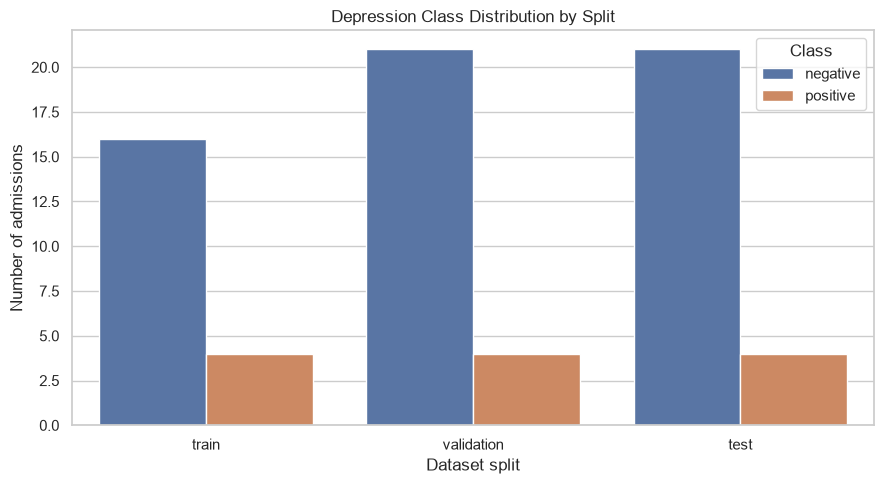

In [9]:
# ============================================================
# CELL 9 - VISUALISE THE WORKING CLASS DISTRIBUTIONS
# ============================================================

class_plot_data = working_split_summary[["split", "negative", "positive"]].melt(
    id_vars="split", var_name="class_name", value_name="admissions"
)
plt.figure(figsize=(9, 5))
sns.barplot(data=class_plot_data, x="split", y="admissions", hue="class_name", order=SPLIT_ORDER)
plt.title(f"{TASK_NAME.title()} Class Distribution by Split")
plt.xlabel("Dataset split")
plt.ylabel("Number of admissions")
plt.legend(title="Class")
plt.tight_layout()
class_distribution_plot_path = FIGURE_DIR / "class_distribution.png"
plt.savefig(class_distribution_plot_path, dpi=200, bbox_inches="tight")
plt.show()

## 4. Load the ClinicalBERT tokenizer and audit input length

Notebook 02 may contain estimated token counts for descriptive analysis. This section performs the model-specific measurement using the exact ClinicalBERT tokenizer used for training.

The audit is completed **before** truncation so the notebook can report how much selected text exceeds the 512-token limit.

In [10]:
# ============================================================
# CELL 10 - LOAD THE CLINICALBERT TOKENIZER
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, cache_dir=str(MODEL_CACHE_DIR), use_fast=True)
print("Tokenizer:", tokenizer.__class__.__name__)
print("Vocabulary size:", f"{tokenizer.vocab_size:,}")
print("Configured maximum length:", MAX_LENGTH)

Tokenizer: BertTokenizer
Vocabulary size: 28,996
Configured maximum length: 512


In [11]:
# ============================================================
# CELL 11 - CALCULATE EXACT CLINICALBERT TOKEN COUNTS
# ============================================================

TOKEN_LENGTH_BATCH_SIZE = 128

def calculate_token_lengths(texts, tokenizer_object, batch_size):
    token_lengths = []
    for batch_start in range(0, len(texts), batch_size):
        batch_texts = texts[batch_start : batch_start + batch_size]
        encoded_batch = tokenizer_object(
            batch_texts,
            add_special_tokens=True,
            truncation=False,
            padding=False,
            return_attention_mask=False,
            return_token_type_ids=False,
        )
        token_lengths.extend(len(input_ids) for input_ids in encoded_batch["input_ids"])

    return token_lengths

token_length_summary_rows = []
for split_name in SPLIT_ORDER:
    split_frame = split_frames[split_name]
    split_frame["clinicalbert_token_count"] = calculate_token_lengths(
        texts=split_frame["model_text"].astype(str).tolist(),
        tokenizer_object=tokenizer,
        batch_size=TOKEN_LENGTH_BATCH_SIZE,
    )
    split_frame["requires_truncation"] = split_frame["clinicalbert_token_count"] > MAX_LENGTH
    token_counts = split_frame["clinicalbert_token_count"]
    truncation_count = int(split_frame["requires_truncation"].sum())
    token_length_summary_rows.append(
        {
            "split": split_name,
            "admissions": len(split_frame),
            "median_tokens": round(token_counts.median(), 1),
            "p95_tokens": round(token_counts.quantile(0.95), 1),
            "maximum_tokens": int(token_counts.max()),
            "notes_over_512": truncation_count,
            "truncation_percentage": round(truncation_count / len(split_frame) * 100, 2),
        }
    )

token_length_summary = pd.DataFrame(token_length_summary_rows)
display(token_length_summary)

,split,admissions,median_tokens,p95_tokens,maximum_tokens,notes_over_512,truncation_percentage
0,train,20,1168.5,2224.2,2247,20,100.0
1,validation,25,986.0,2131.6,3945,22,88.0
2,test,25,942.0,1839.0,1977,21,84.0


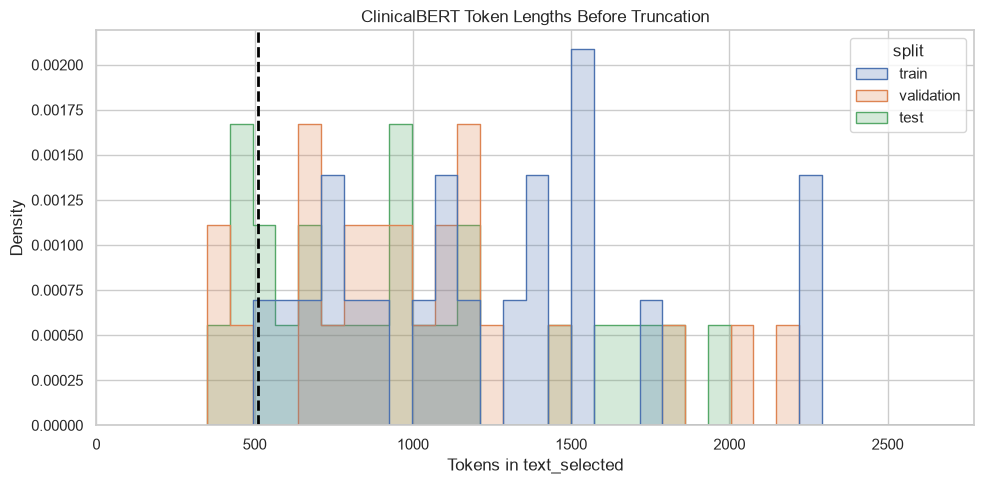

In [12]:
# ============================================================
# CELL 12 - PLOT THE TOKEN-LENGTH DISTRIBUTIONS
# ============================================================

token_plot_frames = []
for split_name in SPLIT_ORDER:
    plot_frame = split_frames[split_name][["clinicalbert_token_count"]].copy()
    plot_frame["split"] = split_name
    token_plot_frames.append(plot_frame)

token_plot_data = pd.concat(token_plot_frames, ignore_index=True)
plot_upper_limit = max(MAX_LENGTH, int(token_plot_data["clinicalbert_token_count"].quantile(0.99)))
plt.figure(figsize=(10, 5))
sns.histplot(
    data=token_plot_data,
    x="clinicalbert_token_count",
    hue="split",
    hue_order=SPLIT_ORDER,
    bins=50,
    element="step",
    stat="density",
    common_norm=False,
)
plt.axvline(MAX_LENGTH, color="black", linestyle="--", linewidth=2, label="ClinicalBERT limit")
plt.xlim(0, plot_upper_limit)
plt.title("ClinicalBERT Token Lengths Before Truncation")
plt.xlabel("Tokens in text_selected")
plt.ylabel("Density")
plt.tight_layout()
token_length_plot_path = FIGURE_DIR / "token_length_distribution.png"
plt.savefig(token_length_plot_path, dpi=200, bbox_inches="tight")
plt.show()

### Representative text examples from each split

For a text-classification project, the equivalent of displaying sample images is to display representative note previews. The cell below shows five reproducible examples from each working split, including both classes where available. It displays only a shortened preview; the complete `model_text` remains unchanged and is still used for tokenisation.


In [13]:
# ============================================================
# CELL 12A - DISPLAY FIVE REPRESENTATIVE RECORDS PER SPLIT
# ============================================================

def select_balanced_examples(frame, sample_size, random_state):
    requested_by_label = {0: (sample_size + 1) // 2, 1: sample_size // 2}
    selected_parts = []

    for label_value, requested_count in requested_by_label.items():
        class_rows = frame.loc[frame["label"].eq(label_value)]
        selected_parts.append(
            class_rows.sample(
                n=min(requested_count, len(class_rows)),
                random_state=random_state + label_value,
            )
        )

    selected = pd.concat(selected_parts)
    if len(selected) < min(sample_size, len(frame)):
        remaining = frame.drop(index=selected.index)
        additional_count = min(sample_size - len(selected), len(remaining))
        selected = pd.concat(
            [selected, remaining.sample(n=additional_count, random_state=random_state + 10)]
        )

    return selected.sample(frac=1.0, random_state=random_state).reset_index(drop=True)


for split_position, split_name in enumerate(SPLIT_ORDER):
    example_records = select_balanced_examples(
        frame=split_frames[split_name],
        sample_size=EXAMPLE_RECORDS_PER_SPLIT,
        random_state=SEED + split_position,
    )
    example_records["label_name"] = example_records["label"].map(
        {0: f"no_{TASK_NAME}", 1: TASK_NAME}
    )
    example_records["text_preview"] = (
        example_records["model_text"]
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.slice(0, 500)
    )

    preview_columns = [
        "subject_id",
        "hadm_id",
        "label",
        "label_name",
        "clinicalbert_token_count",
        "requires_truncation",
        "text_preview",
    ]
    print(f"{split_name.title()} split — {len(example_records)} representative records")
    with pd.option_context("display.max_colwidth", 500):
        display(example_records[preview_columns])


Train split — 5 representative records


,subject_id,hadm_id,label,label_name,clinicalbert_token_count,requires_truncation,text_preview
0,10847927,27379485,0,no_depression,685,True,"past medical history: HTN AAA h/o CVA, no residual effects s/p 6 x C-sections chief complaint: shortness of breath, dyspnea on exertion medications on admission: 1. Ferrous Sulfate 325 mg daily 2. Gabapentin 100 mg QHS 3. Metoprolol tartrate 12.5 mg BID 4. Pantoprazle 40 mg daily 5. Simvastatin 40 mg daily 6. Calcium+Vit D 7. Vitamin C 500 mg daily 8. Centrum Silver discharge medications: 1. Ferrous Sulfate 325 mg (65 mg Iron) Tablet Sig: One (1) Tablet PO DAILY (Daily). 2. Gabapentin 100 mg..."
1,12477344,27054719,1,depression,1395,True,"past medical history: PAST ONCOLOGIC HISTORY 1. Stage II nonsmall cell lung cancer (T3N2Mx adenosquamous carcinoma) harboring an exon 19 deletion EGFR mutation (delE[DEID]A750) 2. Recurrence, metastatic NSCLC adenocarcinoma harboring an exon 19 deletion EGFR mutation (delE746_A750) 1. Status post left upper lobe wedge/anatomical resection and mediastinal lymph node dissection on [DEID] 2. Status post 4 cycles of carboplatin 5 AUC and pemetrexed 500mg/m2 from [DEID] to [DEID] 3. Status post 3..."
2,10370471,26896993,0,no_depression,1203,True,"past medical history: -Hypertension -Renal artery stenosis -Type 2 diabetes, recent HbA1c 7.1%, diet controlled -Hypercholesterolemia -Cataracts chief complaint: Head pressure history of present illness: [DEID] with HTN, HLP, recent diabetes diagnosis, multiple recent admissions for uncontrolled HTN, presenting again with head pressure and severe hypertension. She was admitted to [DEID] [DEID] on [DEID] with severe head pressure. Home BP reading was 230/130. She took losartan 25mg but SBP re..."
3,16784327,25449450,0,no_depression,1766,True,"past medical history: Oncologic History (from previous discharge summary given patient unable to discuss this) --history of adenocarcinoma of unknown source (likely from primary lung cancer) with mets to calvarium, vertebral bodies, lung, and kidney being treated with radiation - [DEID]: Presented to PCP with headache, hip pain, progressive dyspnea on exertion, recent 20lb weight loss, and imaging concerning for metastatic cancer - ct a/p with large left paramediastinal mass and multiple axi..."
4,10873456,26799783,1,depression,1134,True,"past medical history: HTN Perforated gastric ulcer s/p subtotal [DEID] CVA with residual right-sided weakness -[DEID] Hypothyroidism chief complaint: Abdominal pain history of present illness: [DEID] year old male who presents with approximately one week history of malaise, and abdominal pain. He describes the pain as sharp, non-radiating and constant [DEID]. Located periumblical and epigastric area mainly. Started about one week ago and is not associated with food or drinking. Not associate..."


Validation split — 5 representative records


,subject_id,hadm_id,label,label_name,clinicalbert_token_count,requires_truncation,text_preview
0,18734362,28941570,1,depression,1497,True,"past medical history: CHRONIC OBSTRUCTIVE PULMONARY DISEASE ON HOME O2 CHRONIC HYPOXIC RESPIRATORY FAILURE ON HOME O2 OSA on CPAP MORBID OBESITY [DEID] ESOPHAGUS TRAUMA SURVIVOR [MASK] HISTORY OF SI SPINAL STENOSIS chief complaint: fall history of present illness: Upon presentation to the ED patient was noted to have [DEID] weakness. -Vital signs upon presentation: 98.0 86 156/95 18 100% RA -Exam: notable for L sided weakness upon presentation -Labs: Nl CBC, Nl chem 7, U/a negative -Imaging:..."
1,11167081,21729098,0,no_depression,986,True,"past medical history: - CABG [DEID] - Coronary artery disease - Non-Q wave Myocardial Infarction x 2 in [DEID] s/p cath [DEID] with non-flow limiting CAD - Hypertension - Dyslipidemia - Diabetes Mellitus type 2 - Sleep Apnea (C-PAP) - Obesity - Memory Loss - Arthritis - Neuropathy - TIAs no residual, presented as diplopia and resolved after <1hr - Hemorrhoids chief complaint: Abnormal visual changes history of present illness: [DEID] year old male with a history of CAD s/p MI in [DEID] and C..."
2,11976443,29621863,0,no_depression,2018,True,"past medical history: 1. Coronary artery disease, status post stent placement [DEID] on ASA and Plavix x 3 months but taken off in [DEID] secondary to ICh with fall, s/p PCI [DEID] years ago. 2. History of bowel obstruction/volvulus [DEID] s/p abdominal laparatomy with LOA and extensive R colectomy c ileocolic anastomosis [DEID]. 3. Breast cancer. 4. Iron deficiency anemia. 5. Hypertension. 6. Gastroesophageal reflux disease. 7. Hypothyroidism. 8. History of hyponatremia-per pt, has chronic ..."
3,18736150,25251226,0,no_depression,902,True,"past medical history: Bell's palsy (x2 last one [DEID] years ago) Botox treatment to left eye after Bell's palsy Hypertension Hyperlipidemia Critical aortic stenosis BPH Bilateral inguinal hernias, not repaired Herniated disc s/p epidural injection in past with residual right leg/toe numbness Right Achilles tendon tear chief complaint: Right sided weakness history of present illness: [DEID] is an [DEID] year old right handed male with history of HTN, HLD, BPH, AS s/p repair and CABG in [DEID..."
4,18572264,21209586,1,depression,1131,True,"past medical history: Mild pancreatitis s/p ERCP for sludge extraction in [DEID] CAD s/p bare metal stent in [DEID], NSTEMI [DEID] (cath with disease) Hypertension Dyslipidemia [MASK] Hypothyroidism Chronic back pain Oral herpes Left knee meniscus tear chief complaint: Left knee osteoarthritis and pain history of present illness: [DEID] year old female with a history of left knee osteoarthritis and pain presents for surgical intervention. medications on admission: 1. Acyclovir 400 mg PO 3X/D..."


Test split — 5 representative records


,subject_id,hadm_id,label,label_name,clinicalbert_token_count,requires_truncation,text_preview
0,17072596,21302229,0,no_depression,1429,True,"past medical history: DM2 on insulin HTN HLD CKD (baseline Cr 1.2) CAD PVD s/p revascularization on DAPT Gastroparesis H pylori s/p treatment H/o SBO Osteoporosis c/b multiple compression fractures Lumbar radiculopathy Uroepithelial lesion found on CT chief complaint: Abdominal pain, inability to tolerate PO history of present illness: [DEID] female with a history of type 2 DM c/b gastroparesis, CKD (baseline Cr 1.2), HTN, CAD, PAD, chronic abdominal pain, and recently treated H. pylori gast..."
1,19946380,23690922,0,no_depression,1767,True,"past medical history: #1 COPD - last PFTs [DEID] FVC/FEV1 68, FVC 82% pred, FEV1 81% pred. stage I, mild COPD. She reports being on Home O2 for a period of [DEID] months in the past. Her last COPD flare requiring steroids and admission was [DEID] years ago. #2 current tobacco use although cutting back #3 DM II - hgb A1c 7.9, on insulin #4 Obesity #5 Hyperlipidemia #6 Diverticulosis #7 h/o adrenal adenoma #8 herpes simplex #9 hx PE in setting of OCPs 30+ years ago #10 Chronic kidney diease - ..."
2,18210656,22681140,0,no_depression,461,False,"chief complaint: Watery, nonbloody diarrhea history of present illness: Mr. [DEID] is a [DEID] man with history of head and neck cancer. He is currently on docetaxel, cisplatin, and [DEID] who presented with diarrhea. The night before admission, he started having multiple bowel movements with watery, non-bloody diarrhea. Per his wife, he was also increasingly lethargic and nodding off while sitting on the toilet. He denies fevers, chills, or abdominal pain. [DEID] ED, T 98.1, HR 110, BP 116/..."
3,10959084,21423601,1,depression,1707,True,"past medical history: - HTN - HLD - DM type II - CKD stage III (baseline Cr ~1.5) - Parkinsons - Hypothyroidism - GERD - Osteoporosis - H/o colonic adenoma - [MASK] - Lumbar spondylosis - H/o urinary retention chief complaint: toxic-metabolic encephalopathy history of present illness: [DEID] with PMH of [DEID] disease, dementia, DM II, HTN, and a long-standing history of urinary retention/incontinence complicated by recurrent UTIs who presented with altered mental status and a one-week histo..."
4,13605251,27562508,1,depression,1977,True,"past medical history: Crohn's disease Diverticulitis s/p colostomy, and now s/p takeback Recurrent C. difficile colitis ([DEID]) Adrenal Insufficiency - followed by Dr. [DEID] in [DEID] after childbirth. Secondary to insufficiency of ACTH. Hypertension Hyperlipidemia Seizure disorder Avascular necrosis diagnosed in [DEID] Tobacco abuse chief complaint: abdominal pain, nausea, vomiting history of present illness: As per HPI in H&P by Dr. [DEID] [DEID]: ""Ms. [DEID] is a [DEID] female with long..."


## 5. Tokenise and create dynamic batches

ClinicalBERT performs the following model-specific transformations:

1. convert text to WordPiece token IDs;
2. add the model's special tokens;
3. truncate examples longer than 512 tokens;
4. dynamically pad only to the longest sequence in each batch;
5. create attention masks.

The original Parquet files and text fields are not modified.

In [14]:
# ============================================================
# CELL 13 - CONVERT PANDAS SPLITS TO HUGGING FACE DATASETS
# ============================================================

raw_datasets = DatasetDict(
    {
        split_name: Dataset.from_pandas(
            split_frames[split_name][["model_text", "label"]], preserve_index=False
        )
        for split_name in SPLIT_ORDER
    }
)
print(raw_datasets)

DatasetDict({
    train: Dataset({
        features: ['model_text', 'label'],
        num_rows: 20
    })
    validation: Dataset({
        features: ['model_text', 'label'],
        num_rows: 25
    })
    test: Dataset({
        features: ['model_text', 'label'],
        num_rows: 25
    })
})


In [15]:
# ============================================================
# CELL 14 - TOKENISE AND TRUNCATE THE MODEL INPUTS
# ============================================================

def tokenise_batch(batch):
    tokenised_batch = tokenizer(
        batch["model_text"], truncation=True, max_length=MAX_LENGTH, padding=False
    )
    tokenised_batch["labels"] = batch["label"]
    return tokenised_batch

tokenised_datasets = DatasetDict()
for split_name in SPLIT_ORDER:
    tokenised_split = raw_datasets[split_name].map(
        tokenise_batch,
        batched=True,
        remove_columns=raw_datasets[split_name].column_names,
        desc=(f"Tokenising {split_name} data"),
    )
    tokenised_datasets[split_name] = tokenised_split
    maximum_encoded_length = max(len(input_ids) for input_ids in tokenised_split["input_ids"])
    if maximum_encoded_length > MAX_LENGTH:
        raise ValueError(f"A {split_name} input exceeds " f"the {MAX_LENGTH}-token limit.")

    print(
        f"{split_name}: "
        f"{len(tokenised_split):,} examples; "
        f"maximum encoded length = "
        f"{maximum_encoded_length}"
    )

Tokenising train data:   0%|          | 0/20 [00:00<?, ? examples/s]

train: 20 examples; maximum encoded length = 512


Tokenising validation data:   0%|          | 0/25 [00:00<?, ? examples/s]

validation: 25 examples; maximum encoded length = 512


Tokenising test data:   0%|          | 0/25 [00:00<?, ? examples/s]

test: 25 examples; maximum encoded length = 512


In [16]:
# ============================================================
# CELL 15 - CREATE DYNAMIC PADDING AND DATA LOADERS
# ============================================================

PAD_TO_MULTIPLE_OF = 8 if DEVICE.type == "cuda" else None
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer, padding=True, pad_to_multiple_of=PAD_TO_MULTIPLE_OF, return_tensors="pt"
)
data_loader_generator = torch.Generator()
data_loader_generator.manual_seed(SEED)
train_loader = DataLoader(
    tokenised_datasets["train"],
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator,
    generator=data_loader_generator,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
validation_loader = DataLoader(
    tokenised_datasets["validation"],
    batch_size=EVALUATION_BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
test_loader = DataLoader(
    tokenised_datasets["test"],
    batch_size=EVALUATION_BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
example_batch = next(iter(train_loader))
print("Example dynamically padded batch:")
for field_name, field_value in example_batch.items():
    print(field_name, tuple(field_value.shape))

Example dynamically padded batch:
input_ids (2, 512)
token_type_ids (2, 512)
attention_mask (2, 512)
labels (2,)


## 6. Address class imbalance and load the frozen ClinicalBERT baseline

Class weights are calculated from admission-level labels in the training split only. Validation and test labels do not influence the weights.

The pretrained ClinicalBERT base model is frozen immediately after loading. Only the task-specific classification head remains trainable.


In [17]:
# ============================================================
# CELL 16 - CALCULATE TRAINING-ONLY CLASS WEIGHTS
# ============================================================

training_labels = split_frames["train"]["label"].to_numpy(dtype=int)
class_weight_values = compute_class_weight(
    class_weight="balanced", classes=np.array([0, 1]), y=training_labels
)
CLASS_WEIGHTS = torch.tensor(class_weight_values, dtype=torch.float32, device=DEVICE)
class_weight_table = pd.DataFrame(
    {
        "label": [0, 1],
        "training_count": [int((training_labels == 0).sum()), int((training_labels == 1).sum())],
        "class_weight": class_weight_values,
    }
)
display(class_weight_table)

,label,training_count,class_weight
0,0,16,0.625
1,1,4,2.500


In [18]:
# ============================================================
# CELL 17 - LOAD AND FREEZE CLINICALBERT
# ============================================================

ID_TO_LABEL = {0: f"no_{TASK_NAME}", 1: TASK_NAME}
LABEL_TO_ID = {label_name: label_id for label_id, label_name in ID_TO_LABEL.items()}
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=ID_TO_LABEL,
    label2id=LABEL_TO_ID,
    cache_dir=str(MODEL_CACHE_DIR),
)
model.config.problem_type = "single_label_classification"
model.config.training_strategy = TRAINING_STRATEGY
model.config.encoder_frozen_during_training = True

# Freeze every pretrained ClinicalBERT base-model parameter.
base_model = getattr(model, model.base_model_prefix)
for parameter in base_model.parameters():
    parameter.requires_grad = False

# Train only the task-specific classification head.
for parameter in model.classifier.parameters():
    parameter.requires_grad = True

model.to(DEVICE)
total_parameter_count = sum(parameter.numel() for parameter in model.parameters())
trainable_parameter_count = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
frozen_parameter_count = total_parameter_count - trainable_parameter_count

if trainable_parameter_count == 0:
    raise ValueError("No trainable classification-head parameters were found.")
if any(parameter.requires_grad for parameter in base_model.parameters()):
    raise ValueError("At least one ClinicalBERT encoder parameter is still trainable.")
if not all(parameter.requires_grad for parameter in model.classifier.parameters()):
    raise ValueError("At least one classification-head parameter is frozen.")

print("Model class:", model.__class__.__name__)
print("Training strategy:", TRAINING_STRATEGY)
print("Total parameters:", f"{total_parameter_count:,}")
print("Trainable parameters:", f"{trainable_parameter_count:,}")
print("Frozen parameters:", f"{frozen_parameter_count:,}")
print("Verified: the ClinicalBERT encoder is frozen and only the classifier is trainable.")
print(
    "\nA warning about newly initialised classification weights is expected because "
    "the task-specific head must be trained."
)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

Model class: BertForSequenceClassification
Training strategy: frozen_encoder_classifier_only
Total parameters: 108,311,810
Trainable parameters: 1,538
Frozen parameters: 108,310,272
Verified: the ClinicalBERT encoder is frozen and only the classifier is trainable.

A warning about newly initialised classification weights is expected because the task-specific head must be trained.


### ClinicalBERT construction in one place

The following cell consolidates the model configuration, complete PyTorch module structure, component-level parameter counts, and encoder-layer parameter counts. It documents exactly which parameters are frozen and which parameters are trainable, but it does not change the model.


In [19]:
# ============================================================
# CELL 17A - DISPLAY FROZEN-BASELINE MODEL CONSTRUCTION
# ============================================================

base_model = getattr(model, model.base_model_prefix)
encoder_layers = base_model.encoder.layer

model_configuration = pd.DataFrame(
    {
        "property": [
            "Model class",
            "Base-model prefix",
            "Vocabulary size",
            "Hidden size",
            "Transformer encoder layers",
            "Attention heads per layer",
            "Intermediate feed-forward size",
            "Maximum position embeddings",
            "Hidden dropout probability",
            "Attention dropout probability",
            "Output labels",
            "Total parameters",
            "Trainable parameters",
            "Frozen parameters",
        ],
        "value": [
            model.__class__.__name__,
            model.base_model_prefix,
            model.config.vocab_size,
            model.config.hidden_size,
            model.config.num_hidden_layers,
            model.config.num_attention_heads,
            model.config.intermediate_size,
            model.config.max_position_embeddings,
            model.config.hidden_dropout_prob,
            model.config.attention_probs_dropout_prob,
            model.config.num_labels,
            f"{total_parameter_count:,}",
            f"{trainable_parameter_count:,}",
            f"{total_parameter_count - trainable_parameter_count:,}",
        ],
    }
)
display(model_configuration)

component_parameter_rows = []
for component_name, component in model.named_children():
    component_parameter_rows.append(
        {
            "component": component_name,
            "module_type": component.__class__.__name__,
            "parameters": sum(parameter.numel() for parameter in component.parameters()),
            "trainable_parameters": sum(
                parameter.numel()
                for parameter in component.parameters()
                if parameter.requires_grad
            ),
        }
    )

print("Top-level components:")
display(pd.DataFrame(component_parameter_rows))

encoder_layer_rows = []
for layer_number, encoder_layer in enumerate(encoder_layers, start=1):
    encoder_layer_rows.append(
        {
            "encoder_layer": layer_number,
            "parameters": sum(parameter.numel() for parameter in encoder_layer.parameters()),
            "trainable_parameters": sum(
                parameter.numel()
                for parameter in encoder_layer.parameters()
                if parameter.requires_grad
            ),
        }
    )

print("Transformer encoder layers:")
display(pd.DataFrame(encoder_layer_rows))

# Capture the output shape of every leaf module with one example.
layer_summary_rows = []
summary_hooks = []

def format_output_shape(output_value):
    if isinstance(output_value, torch.Tensor):
        return str(tuple(output_value.shape))
    if isinstance(output_value, (tuple, list)):
        return str(
            [tuple(value.shape) for value in output_value if isinstance(value, torch.Tensor)]
        )
    return type(output_value).__name__

def make_summary_hook(module_name):
    def summary_hook(module, inputs, output):
        direct_parameters = list(module.parameters(recurse=False))
        layer_summary_rows.append(
            {
                "layer": module_name,
                "module_type": module.__class__.__name__,
                "output_shape": format_output_shape(output),
                "parameters": sum(parameter.numel() for parameter in direct_parameters),
                "trainable_parameters": sum(
                    parameter.numel() for parameter in direct_parameters if parameter.requires_grad
                ),
            }
        )
    return summary_hook

for module_name, module in model.named_modules():
    if module_name and not any(module.children()):
        summary_hooks.append(module.register_forward_hook(make_summary_hook(module_name)))

summary_batch = {
    field_name: field_value[:1].to(DEVICE)
    for field_name, field_value in example_batch.items()
    if field_name != "labels"
}
model.eval()
with torch.no_grad():
    model(**summary_batch)

for hook in summary_hooks:
    hook.remove()

layer_summary_table = pd.DataFrame(layer_summary_rows)
print(f"Leaf-module summary ({len(layer_summary_table)} executed modules):")
display(
    HTML(
        '<div style="max-height: 600px; overflow: auto; border: 1px solid #bbb; '
        'padding: 6px;">'
        + layer_summary_table.to_html(index=False)
        + "</div>"
    )
)

print("Complete PyTorch construction (expand and scroll):")
display(
    HTML(
        '<details><summary>Open complete model construction</summary>'
        '<div style="max-height: 600px; overflow: auto; border: 1px solid #bbb; '
        'padding: 10px;"><pre>'
        + html.escape(str(model))
        + "</pre></div></details>"
    )
)


,property,value
0,Model class,BertForSequenceClassification
1,Base-model prefix,bert
2,Vocabulary size,28996
3,Hidden size,768
4,Transformer encoder layers,12
5,Attention heads per layer,12
6,Intermediate feed-forward size,3072
7,Maximum position embeddings,512
8,Hidden dropout probability,0.1
9,Attention dropout probability,0.1


Top-level components:


,component,module_type,parameters,trainable_parameters
0,bert,BertModel,108310272,0
1,dropout,Dropout,0,0
2,classifier,Linear,1538,1538


Transformer encoder layers:


,encoder_layer,parameters,trainable_parameters
0,1,7087872,0
1,2,7087872,0
2,3,7087872,0
3,4,7087872,0
4,5,7087872,0
5,6,7087872,0
6,7,7087872,0
7,8,7087872,0
8,9,7087872,0
9,10,7087872,0


Leaf-module summary (141 executed modules):


layer,module_type,output_shape,parameters,trainable_parameters
bert.embeddings.word_embeddings,Embedding,"(1, 512, 768)",22268928,0
bert.embeddings.token_type_embeddings,Embedding,"(1, 512, 768)",1536,0
bert.embeddings.position_embeddings,Embedding,"(1, 512, 768)",393216,0
bert.embeddings.LayerNorm,LayerNorm,"(1, 512, 768)",1536,0
bert.embeddings.dropout,Dropout,"(1, 512, 768)",0,0
bert.encoder.layer.0.attention.self.query,Linear,"(1, 512, 768)",590592,0
bert.encoder.layer.0.attention.self.key,Linear,"(1, 512, 768)",590592,0
bert.encoder.layer.0.attention.self.value,Linear,"(1, 512, 768)",590592,0
bert.encoder.layer.0.attention.output.dense,Linear,"(1, 512, 768)",590592,0
bert.encoder.layer.0.attention.output.dropout,Dropout,"(1, 512, 768)",0,0


Complete PyTorch construction (expand and scroll):


In [20]:
# ============================================================
# CELL 18 - VERIFY ONE FORWARD PASS
# ============================================================

forward_batch = {
    field_name: field_value.to(DEVICE) for field_name, field_value in example_batch.items()
}
forward_labels = forward_batch.pop("labels")
model.eval()
with torch.no_grad():
    forward_outputs = model(**forward_batch)
    forward_logits = forward_outputs.logits
    forward_loss = F.cross_entropy(forward_logits, forward_labels, weight=CLASS_WEIGHTS)

if forward_logits.shape != (len(forward_labels), 2):
    raise ValueError("The model returned an unexpected logits shape.")

if not torch.isfinite(forward_loss):
    raise ValueError("The forward-pass loss is not finite.")

print("Forward-pass logits shape:", tuple(forward_logits.shape))
print("Weighted loss:", round(forward_loss.item(), 6))
print("ClinicalBERT forward-pass test passed.")

Forward-pass logits shape: (2, 2)
Weighted loss: 0.768695
ClinicalBERT forward-pass test passed.


### Capture pre-training weights for frozen-baseline verification

`requires_grad=False` shows that the pretrained encoder is excluded from optimisation, but the notebook also performs a stronger before-and-after audit. It fingerprints every parameter tensor and stores exact copies of representative weights from the embeddings, early/middle/final encoder layers, and classification head. After training, the encoder tensors must remain unchanged and the classification head must change.


In [21]:
# ============================================================
# CELL 18A - CAPTURE PRE-TRAINING PARAMETER VALUES
# ============================================================

def calculate_parameter_fingerprint(parameter):
    parameter_bytes = (
        parameter
        .detach()
        .cpu()
        .contiguous()
        .view(torch.uint8)
        .numpy()
        .tobytes()
    )
    return hashlib.sha256(parameter_bytes).hexdigest()


named_parameters_before_training = dict(model.named_parameters())

representative_parameter_roles = {
    "token_embeddings": "bert.embeddings.word_embeddings.weight",
    "encoder_layer_1_attention": "bert.encoder.layer.0.attention.self.query.weight",
    "encoder_layer_6_output": "bert.encoder.layer.5.output.dense.weight",
    "encoder_layer_12_output": "bert.encoder.layer.11.output.dense.weight",
    "classification_head": "classifier.weight",
}

missing_representative_parameters = [
    parameter_name
    for parameter_name in representative_parameter_roles.values()
    if parameter_name not in named_parameters_before_training
]
if missing_representative_parameters:
    raise KeyError(
        "Could not find the expected ClinicalBERT parameters: "
        f"{missing_representative_parameters}"
    )

print("Fingerprinting every model parameter tensor before training...")
initial_parameter_fingerprints = {
    parameter_name: calculate_parameter_fingerprint(parameter)
    for parameter_name, parameter in tqdm(
        named_parameters_before_training.items(),
        desc="Pre-training fingerprints",
        unit="tensor",
    )
}

initial_parameter_snapshots = {
    role_name: named_parameters_before_training[parameter_name].detach().cpu().clone()
    for role_name, parameter_name in representative_parameter_roles.items()
}

pretraining_parameter_table = pd.DataFrame(
    [
        {
            "role": role_name,
            "parameter": parameter_name,
            "shape": str(tuple(named_parameters_before_training[parameter_name].shape)),
            "values": named_parameters_before_training[parameter_name].numel(),
            "requires_grad": named_parameters_before_training[parameter_name].requires_grad,
            "expected_after_training": (
                "changed" if named_parameters_before_training[parameter_name].requires_grad
                else "unchanged"
            ),
        }
        for role_name, parameter_name in representative_parameter_roles.items()
    ]
)

display(pretraining_parameter_table)
print("All parameter tensors fingerprinted:", len(initial_parameter_fingerprints))
print("Exact representative snapshots stored on CPU:", len(initial_parameter_snapshots))


Fingerprinting every model parameter tensor before training...


Pre-training fingerprints:   0%|          | 0/201 [00:00<?, ?tensor/s]

,role,parameter,shape,values,requires_grad,expected_after_training
0,token_embeddings,bert.embeddings.word_embeddings.weight,"(28996, 768)",22268928,False,unchanged
1,encoder_layer_1_attention,bert.encoder.layer.0.attention.self.query.weight,"(768, 768)",589824,False,unchanged
2,encoder_layer_6_output,bert.encoder.layer.5.output.dense.weight,"(768, 3072)",2359296,False,unchanged
3,encoder_layer_12_output,bert.encoder.layer.11.output.dense.weight,"(768, 3072)",2359296,False,unchanged
4,classification_head,classifier.weight,"(2, 768)",1536,True,changed


All parameter tensors fingerprinted: 201
Exact representative snapshots stored on CPU: 5


## 7. Define evaluation and threshold-selection functions

Because the positive class is imbalanced, the notebook reports both conventional classification metrics and ranking metrics:

- accuracy and balanced accuracy;
- precision, recall, F1, and specificity;
- ROC-AUC;
- PR-AUC (average precision).

The validation threshold is chosen to maximise validation F1. That threshold is then frozen and applied unchanged to the test probabilities.

In [22]:
# ============================================================
# CELL 19 - DEFINE CLASSIFICATION METRICS
# ============================================================

def safe_auc_score(score_function, labels, probabilities):
    if len(np.unique(labels)) < 2:
        return float("nan")

    return float(score_function(labels, probabilities))

def calculate_classification_metrics(labels, positive_probabilities, threshold):
    labels = np.asarray(labels, dtype=int)
    positive_probabilities = np.asarray(positive_probabilities, dtype=float)
    predictions = (positive_probabilities >= threshold).astype(int)
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()
    specificity_denominator = true_negative + false_positive
    specificity = (
        true_negative / specificity_denominator if specificity_denominator > 0 else float("nan")
    )
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(labels, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predictions)),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "specificity": float(specificity),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "roc_auc": safe_auc_score(roc_auc_score, labels, positive_probabilities),
        "pr_auc": safe_auc_score(average_precision_score, labels, positive_probabilities),
        "true_negative": int(true_negative),
        "false_positive": int(false_positive),
        "false_negative": int(false_negative),
        "true_positive": int(true_positive),
    }

In [23]:
# ============================================================
# CELL 20 - DEFINE VALIDATION THRESHOLD SELECTION
# ============================================================

def select_f1_threshold(labels, positive_probabilities):
    precision_values, recall_values, threshold_values = precision_recall_curve(
        labels, positive_probabilities
    )
    if len(threshold_values) == 0:
        return 0.5, float("nan"), pd.DataFrame()

    precision_for_thresholds = precision_values[:-1]
    recall_for_thresholds = recall_values[:-1]
    f1_values = (
        2
        * precision_for_thresholds
        * recall_for_thresholds
        / np.clip(precision_for_thresholds + recall_for_thresholds, a_min=1e-12, a_max=None)
    )
    best_position = int(np.nanargmax(f1_values))
    threshold_table = pd.DataFrame(
        {
            "threshold": threshold_values,
            "precision": precision_for_thresholds,
            "recall": recall_for_thresholds,
            "f1": f1_values,
        }
    )
    return (
        float(threshold_values[best_position]),
        float(f1_values[best_position]),
        threshold_table,
    )

In [24]:
# ============================================================
# CELL 21 - DEFINE MODEL EVALUATION
# ============================================================

PROGRESS_BAR_FORMAT = (
    "{desc}: {percentage:3.0f}%|{bar:32}| "
    "{n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}{postfix}]"
)

def evaluate_model(model_object, data_loader, class_weights, progress_description=None):
    model_object.eval()
    all_labels = []
    all_probabilities = []
    total_weighted_loss = 0.0
    total_class_weight = 0.0

    if progress_description is None:
        evaluation_batches = data_loader
    else:
        evaluation_batches = tqdm(
            data_loader,
            total=len(data_loader),
            desc=progress_description,
            leave=False,
            dynamic_ncols=True,
            unit="batch",
            bar_format=PROGRESS_BAR_FORMAT,
        )

    with torch.no_grad():
        for batch in evaluation_batches:
            labels = batch["labels"].to(DEVICE)
            model_inputs = {
                field_name: field_value.to(DEVICE)
                for field_name, field_value in batch.items()
                if field_name != "labels"
            }
            logits = model_object(**model_inputs).logits
            per_example_loss = F.cross_entropy(
                logits,
                labels,
                weight=class_weights,
                reduction="none",
            )
            example_class_weights = class_weights[labels]
            total_weighted_loss += float(per_example_loss.sum().item())
            total_class_weight += float(example_class_weights.sum().item())
            positive_probabilities = torch.softmax(logits, dim=-1)[:, 1]
            all_labels.extend(labels.detach().cpu().numpy().tolist())
            all_probabilities.extend(positive_probabilities.detach().cpu().numpy().tolist())

    mean_weighted_loss = total_weighted_loss / max(total_class_weight, 1e-12)
    return (
        mean_weighted_loss,
        np.asarray(all_labels, dtype=int),
        np.asarray(all_probabilities, dtype=float),
    )


## 8. Configure and train the ClinicalBERT frozen-encoder baseline

Only the classification head is optimised. The pretrained ClinicalBERT encoder stays frozen and is kept in evaluation mode during head training so its dropout layers do not create changing feature representations.

The best checkpoint is selected using validation PR-AUC because the positive class is imbalanced. During each epoch, a progress bar displays completed batches, running loss, running training accuracy, learning rate, elapsed time, and estimated time remaining. At the end of every epoch, the notebook displays training accuracy together with validation accuracy, balanced accuracy, precision, recall, F1, ROC-AUC, and PR-AUC.

The test loader is not used anywhere in the training loop.

### Checkpoint and early-stopping policy

Validation PR-AUC is monitored after every epoch. An improvement must exceed `EARLY_STOPPING_MINIMUM_IMPROVEMENT`, while `EARLY_STOPPING_PATIENCE` controls how many consecutive non-improving epochs are tolerated.

By default, `STOP_TRAINING_WHEN_PATIENCE_REACHED = False`. Therefore, all requested epochs run. The notebook still records the first epoch at which the patience rule would have stopped training and saves that state separately. It also saves the best-validation checkpoint and the final-epoch checkpoint. The best-validation checkpoint remains the recommended model for test evaluation and deployment.


In [25]:
# ============================================================
# CELL 22 - CONFIGURE CLASSIFIER-ONLY OPTIMISER AND SCHEDULE
# ============================================================

trainable_parameters = [
    parameter for parameter in model.parameters() if parameter.requires_grad
]
optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

trainable_parameter_ids = {
    id(parameter)
    for parameter in model.parameters()
    if parameter.requires_grad
}
optimizer_parameter_ids = {
    id(parameter)
    for parameter_group in optimizer.param_groups
    for parameter in parameter_group["params"]
}
missing_optimizer_parameter_count = len(
    trainable_parameter_ids - optimizer_parameter_ids
)

if missing_optimizer_parameter_count > 0:
    raise ValueError(
        f"{missing_optimizer_parameter_count} trainable parameters "
        "were not included in the optimiser."
    )

if any(id(parameter) in optimizer_parameter_ids for parameter in base_model.parameters()):
    raise ValueError("A frozen encoder parameter was included in the optimiser.")

print("Verified: the optimiser contains only classification-head parameters.")
updates_per_epoch = max(1, math.ceil(len(train_loader) / GRADIENT_ACCUMULATION_STEPS))
total_training_steps = updates_per_epoch * NUMBER_OF_EPOCHS
warmup_steps = int(round(total_training_steps * WARMUP_PROPORTION))
scheduler = get_linear_schedule_with_warmup(
    optimizer=optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_training_steps
)
AMP_ENABLED = bool(USE_MIXED_PRECISION and DEVICE.type == "cuda")
gradient_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED,
)
training_schedule_table = pd.DataFrame(
    {
        "setting": [
            "Training batches per epoch",
            "Gradient accumulation steps",
            "Optimiser updates per epoch",
            "Total optimiser updates",
            "Warm-up updates",
            "Mixed precision",
        ],
        "value": [
            len(train_loader),
            GRADIENT_ACCUMULATION_STEPS,
            updates_per_epoch,
            total_training_steps,
            warmup_steps,
            AMP_ENABLED,
        ],
    }
)
display(training_schedule_table)

Verified: the optimiser contains only classification-head parameters.


,setting,value
0,Training batches per epoch,10
1,Gradient accumulation steps,8
2,Optimiser updates per epoch,2
3,Total optimiser updates,2
4,Warm-up updates,0
5,Mixed precision,False


In [26]:
# ============================================================
# CELL 23 - DEFINE ONE TRAINING EPOCH
# ============================================================

def format_duration(total_seconds):
    total_seconds = max(0, int(round(total_seconds)))
    hours, remainder = divmod(total_seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    if hours:
        return f"{hours:d}h {minutes:02d}m {seconds:02d}s"
    if minutes:
        return f"{minutes:d}m {seconds:02d}s"
    return f"{seconds:d}s"


def train_one_epoch(
    model_object,
    data_loader,
    optimizer_object,
    scheduler_object,
    class_weights,
    gradient_scaler_object,
    epoch_number,
    total_epochs,
):
    model_object.train()
    frozen_base_model = getattr(model_object, model_object.base_model_prefix)
    frozen_base_model.eval()
    optimizer_object.zero_grad(set_to_none=True)
    total_weighted_loss = 0.0
    total_class_weight = 0.0
    correct_prediction_count = 0
    processed_example_count = 0
    training_start_time = time.time()

    print(f"\nEpoch {epoch_number}/{total_epochs}")
    progress_bar = tqdm(
        data_loader,
        total=len(data_loader),
        desc="Training",
        leave=True,
        dynamic_ncols=True,
        unit="batch",
        bar_format=PROGRESS_BAR_FORMAT,
    )

    for batch_position, batch in enumerate(progress_bar):
        labels = batch["labels"].to(DEVICE)
        model_inputs = {
            field_name: field_value.to(DEVICE)
            for field_name, field_value in batch.items()
            if field_name != "labels"
        }

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):
            logits = model_object(**model_inputs).logits
            per_example_loss = F.cross_entropy(
                logits,
                labels,
                weight=class_weights,
                reduction="none",
            )
            example_class_weights = class_weights[labels]
            batch_loss = per_example_loss.sum() / example_class_weights.sum().clamp_min(1e-12)
            accumulation_loss = batch_loss / GRADIENT_ACCUMULATION_STEPS

        gradient_scaler_object.scale(accumulation_loss).backward()
        is_accumulation_boundary = (batch_position + 1) % GRADIENT_ACCUMULATION_STEPS == 0
        is_final_batch = batch_position + 1 == len(data_loader)

        if is_accumulation_boundary or is_final_batch:
            gradient_scaler_object.unscale_(optimizer_object)
            clip_grad_norm_(
                (parameter for parameter in model_object.parameters() if parameter.requires_grad),
                MAX_GRADIENT_NORM,
            )
            gradient_scaler_object.step(optimizer_object)
            gradient_scaler_object.update()
            scheduler_object.step()
            optimizer_object.zero_grad(set_to_none=True)

        batch_predictions = logits.argmax(dim=-1)
        correct_prediction_count += int((batch_predictions == labels).sum().item())
        processed_example_count += int(labels.size(0))
        total_weighted_loss += float(per_example_loss.detach().sum().item())
        total_class_weight += float(example_class_weights.detach().sum().item())

        running_loss = total_weighted_loss / max(total_class_weight, 1e-12)
        running_accuracy = correct_prediction_count / max(processed_example_count, 1)
        progress_bar.set_postfix(
            loss=f"{running_loss:.4f}",
            accuracy=f"{running_accuracy:.4f}",
            learning_rate=f"{scheduler_object.get_last_lr()[0]:.2e}",
        )

    training_seconds = time.time() - training_start_time
    mean_training_loss = total_weighted_loss / max(total_class_weight, 1e-12)
    training_accuracy = correct_prediction_count / max(processed_example_count, 1)
    milliseconds_per_batch = training_seconds * 1_000 / max(len(data_loader), 1)

    return (
        mean_training_loss,
        training_accuracy,
        training_seconds,
        milliseconds_per_batch,
    )


In [27]:
# ============================================================
# CELL 24 - TRAIN CLASSIFIER AND SAVE CHECKPOINTS
# ============================================================

training_history_rows = []
best_validation_pr_auc = -float("inf")
best_epoch = None
early_stop_signal_epoch = None
last_completed_epoch = None
epochs_without_improvement = 0
training_start_time = time.time()

for epoch_number in range(1, NUMBER_OF_EPOCHS + 1):
    epoch_start_time = time.time()
    (
        training_loss,
        training_accuracy,
        training_seconds,
        milliseconds_per_batch,
    ) = train_one_epoch(
        model_object=model,
        data_loader=train_loader,
        optimizer_object=optimizer,
        scheduler_object=scheduler,
        class_weights=CLASS_WEIGHTS,
        gradient_scaler_object=gradient_scaler,
        epoch_number=epoch_number,
        total_epochs=NUMBER_OF_EPOCHS,
    )

    validation_loss, validation_labels_for_epoch, validation_probabilities_for_epoch = (
        evaluate_model(
            model_object=model,
            data_loader=validation_loader,
            class_weights=CLASS_WEIGHTS,
            progress_description=f"Validating epoch {epoch_number}",
        )
    )
    validation_metrics_for_epoch = calculate_classification_metrics(
        labels=validation_labels_for_epoch,
        positive_probabilities=validation_probabilities_for_epoch,
        threshold=0.5,
    )
    validation_pr_auc = validation_metrics_for_epoch["pr_auc"]
    epoch_duration_seconds = time.time() - epoch_start_time
    last_completed_epoch = epoch_number

    epoch_result = {
        "epoch": epoch_number,
        "training_loss": training_loss,
        "training_accuracy": training_accuracy,
        "validation_loss": validation_loss,
        "validation_accuracy": validation_metrics_for_epoch["accuracy"],
        "validation_balanced_accuracy": validation_metrics_for_epoch["balanced_accuracy"],
        "validation_precision": validation_metrics_for_epoch["precision"],
        "validation_recall": validation_metrics_for_epoch["recall"],
        "validation_f1_at_0_5": validation_metrics_for_epoch["f1"],
        "validation_roc_auc": validation_metrics_for_epoch["roc_auc"],
        "validation_pr_auc": validation_pr_auc,
        "training_seconds": training_seconds,
        "milliseconds_per_batch": milliseconds_per_batch,
        "epoch_seconds": epoch_duration_seconds,
    }
    training_history_rows.append(epoch_result)

    print(
        f"{len(train_loader)}/{len(train_loader)} - "
        f"{format_duration(epoch_duration_seconds)} - "
        f"{milliseconds_per_batch:.0f}ms/batch - "
        f"loss: {training_loss:.4f} - "
        f"accuracy: {training_accuracy:.4f} - "
        f"val_loss: {validation_loss:.4f} - "
        f"val_accuracy: {epoch_result['validation_accuracy']:.4f} - "
        f"val_f1: {epoch_result['validation_f1_at_0_5']:.4f} - "
        f"val_pr_auc: {validation_pr_auc:.4f}"
    )

    mean_epoch_seconds = np.mean([row["epoch_seconds"] for row in training_history_rows])
    maximum_remaining_epochs = NUMBER_OF_EPOCHS - epoch_number
    print(
        "Estimated maximum time remaining if all requested epochs run:",
        format_duration(mean_epoch_seconds * maximum_remaining_epochs),
    )

    validation_improved = (
        validation_pr_auc
        > best_validation_pr_auc + EARLY_STOPPING_MINIMUM_IMPROVEMENT
    )

    if validation_improved:
        best_validation_pr_auc = validation_pr_auc
        best_epoch = epoch_number
        epochs_without_improvement = 0
        model.save_pretrained(BEST_MODEL_DIR, safe_serialization=True)
        tokenizer.save_pretrained(BEST_MODEL_DIR)
        print("Saved a new best-validation checkpoint.")
    else:
        epochs_without_improvement += 1
        print(
            "Validation PR-AUC did not improve by at least "
            f"{EARLY_STOPPING_MINIMUM_IMPROVEMENT:g} "
            f"({epochs_without_improvement}/{EARLY_STOPPING_PATIENCE})."
        )

        patience_reached = epochs_without_improvement >= EARLY_STOPPING_PATIENCE
        if patience_reached and early_stop_signal_epoch is None:
            early_stop_signal_epoch = epoch_number

            if SAVE_EARLY_STOP_SIGNAL_MODEL:
                model.save_pretrained(
                    EARLY_STOP_SIGNAL_MODEL_DIR,
                    safe_serialization=True,
                )
                tokenizer.save_pretrained(EARLY_STOP_SIGNAL_MODEL_DIR)

            print(
                "Early-stopping patience was first reached at epoch",
                early_stop_signal_epoch,
            )
            print(
                "The best-validation model remains the checkpoint from epoch",
                best_epoch,
            )

            if STOP_TRAINING_WHEN_PATIENCE_REACHED:
                print("Training stopped because the stopping option is enabled.")
                break
            else:
                print("Training will continue because the stopping option is disabled.")

# Save the state from the last epoch that actually ran.
model.save_pretrained(FINAL_EPOCH_MODEL_DIR, safe_serialization=True)
tokenizer.save_pretrained(FINAL_EPOCH_MODEL_DIR)

total_training_seconds = time.time() - training_start_time
training_history = pd.DataFrame(training_history_rows)
training_history.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

print("\nComplete epoch history:")
display(training_history.round(6))
print("Best-validation epoch:", best_epoch)
print("Best validation PR-AUC:", round(best_validation_pr_auc, 6))
print("Early-stop signal epoch:", early_stop_signal_epoch)
print("Last completed epoch:", last_completed_epoch)
print("Total training time:", format_duration(total_training_seconds))
print("\nSaved checkpoint meanings:")
print("Best validation model:", BEST_MODEL_DIR)
print("Early-stop signal model:", EARLY_STOP_SIGNAL_MODEL_DIR)
print("Final completed epoch model:", FINAL_EPOCH_MODEL_DIR)



Epoch 1/1


Training:   0%|                                | 0/10 [00:00<?, ?batch/s]

Validating epoch 1:   0%|                                | 0/7 [00:00<?, ?batch/

10/10 - 3s - 133ms/batch - loss: 0.6959 - accuracy: 0.3000 - val_loss: 0.7101 - val_accuracy: 0.2400 - val_f1: 0.2963 - val_pr_auc: 0.1768
Estimated maximum time remaining if all requested epochs run: 0s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved a new best-validation checkpoint.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Complete epoch history:


,epoch,training_loss,training_accuracy,validation_loss,validation_accuracy,validation_balanced_accuracy,validation_precision,validation_recall,validation_f1_at_0_5,validation_roc_auc,validation_pr_auc,training_seconds,milliseconds_per_batch,epoch_seconds
0,1,0.695922,0.3,0.710095,0.24,0.547619,0.173913,1.0,0.296296,0.452381,0.176812,1.333325,133.332467,2.761151


Best-validation epoch: 1
Best validation PR-AUC: 0.176812
Early-stop signal epoch: None
Last completed epoch: 1
Total training time: 3s

Saved checkpoint meanings:
Best validation model: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/clinicalbert_frozen_baseline/clinicalbert_frozen_baseline_depression_masked_selected_smoke/best_model
Early-stop signal model: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/clinicalbert_frozen_baseline/clinicalbert_frozen_baseline_depression_masked_selected_smoke/early_stop_signal_model
Final completed epoch model: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/clinicalbert_frozen_baseline/clinicalbert_frozen_baseline_depression_masked_selected_smoke/final_epoch_model


### Verify the frozen-encoder baseline after training

The full fingerprint audit verifies the intended comparison condition. Every pretrained embedding, encoder, and pooler tensor must remain unchanged. The task-specific classification head must change. This demonstrates classifier-only training rather than full-model fine-tuning.


In [28]:
# ============================================================
# CELL 24A - VERIFY FROZEN ENCODER AND TRAINED HEAD
# ============================================================

def identify_parameter_component(parameter_name):
    if parameter_name.startswith("bert.embeddings"):
        return "Embeddings"
    if ".encoder.layer." in parameter_name:
        layer_text = parameter_name.split(".encoder.layer.", 1)[1].split(".", 1)[0]
        return f"Encoder layer {int(layer_text) + 1}"
    if parameter_name.startswith("bert.pooler"):
        return "Pooler"
    if parameter_name.startswith("classifier"):
        return "Classification head"
    return "Other"


named_parameters_after_training = dict(model.named_parameters())
full_parameter_audit_rows = []

print("Fingerprinting every model parameter tensor after training...")
for parameter_name, initial_fingerprint in tqdm(
    initial_parameter_fingerprints.items(),
    desc="Post-training fingerprints",
    unit="tensor",
):
    current_parameter = named_parameters_after_training[parameter_name]
    fingerprint_changed = (
        calculate_parameter_fingerprint(current_parameter) != initial_fingerprint
    )
    full_parameter_audit_rows.append(
        {
            "component": identify_parameter_component(parameter_name),
            "parameter": parameter_name,
            "values": current_parameter.numel(),
            "requires_grad": current_parameter.requires_grad,
            "fingerprint_changed": fingerprint_changed,
            "expected_change": current_parameter.requires_grad,
            "matches_expected_state": (
                fingerprint_changed == current_parameter.requires_grad
            ),
        }
    )

full_parameter_audit = pd.DataFrame(full_parameter_audit_rows)
component_freeze_summary = (
    full_parameter_audit
    .groupby("component", as_index=False)
    .agg(
        parameter_tensors=("parameter", "count"),
        trainable_tensors=("requires_grad", "sum"),
        changed_tensors=("fingerprint_changed", "sum"),
        matching_tensors=("matches_expected_state", "sum"),
        parameter_values=("values", "sum"),
    )
)
component_freeze_summary["expected_state_match_percentage"] = (
    component_freeze_summary["matching_tensors"]
    / component_freeze_summary["parameter_tensors"]
    * 100
)

print("Frozen-baseline fingerprint summary:")
display(component_freeze_summary.round(2))

representative_change_rows = []
for role_name, parameter_name in representative_parameter_roles.items():
    initial_value = initial_parameter_snapshots[role_name]
    current_value = named_parameters_after_training[parameter_name].detach().cpu()
    absolute_change = (current_value - initial_value).abs()
    initial_norm = torch.linalg.vector_norm(initial_value.float())
    change_norm = torch.linalg.vector_norm((current_value - initial_value).float())
    requires_grad = named_parameters_after_training[parameter_name].requires_grad

    representative_change_rows.append(
        {
            "role": role_name,
            "parameter": parameter_name,
            "requires_grad": requires_grad,
            "expected_change": requires_grad,
            "maximum_absolute_change": float(absolute_change.max()),
            "mean_absolute_change": float(absolute_change.float().mean()),
            "relative_l2_change": float(change_norm / initial_norm.clamp_min(1e-12)),
            "changed_value_percentage": float(absolute_change.ne(0).float().mean() * 100),
            "parameter_changed": bool(absolute_change.ne(0).any()),
        }
    )

representative_weight_changes = pd.DataFrame(representative_change_rows)
representative_weight_changes["matches_expected_state"] = (
    representative_weight_changes["parameter_changed"]
    == representative_weight_changes["expected_change"]
)
print("Exact representative before/after comparisons:")
display(representative_weight_changes)

base_roles = [
    "token_embeddings",
    "encoder_layer_1_attention",
    "encoder_layer_6_output",
    "encoder_layer_12_output",
]
base_layers_unchanged = (~representative_weight_changes.loc[
    representative_weight_changes["role"].isin(base_roles),
    "parameter_changed",
]).all()
classification_head_changed = representative_weight_changes.loc[
    representative_weight_changes["role"].eq("classification_head"),
    "parameter_changed",
].all()
all_frozen_tensors_unchanged = (~full_parameter_audit.loc[
    ~full_parameter_audit["requires_grad"],
    "fingerprint_changed",
]).all()
any_trainable_tensor_changed = full_parameter_audit.loc[
    full_parameter_audit["requires_grad"],
    "fingerprint_changed",
].any()
FROZEN_BASELINE_VERIFIED = bool(
    base_layers_unchanged
    and classification_head_changed
    and all_frozen_tensors_unchanged
    and any_trainable_tensor_changed
)

full_parameter_audit.to_csv(
    OUTPUT_DIR / "frozen_baseline_full_parameter_audit.csv",
    index=False,
)
component_freeze_summary.to_csv(
    OUTPUT_DIR / "frozen_baseline_component_summary.csv",
    index=False,
)
representative_weight_changes.to_csv(
    OUTPUT_DIR / "frozen_baseline_representative_weight_changes.csv",
    index=False,
)

if FROZEN_BASELINE_VERIFIED:
    print("Verified: every frozen ClinicalBERT tensor remained unchanged.")
    print("Verified: the task-specific classification head changed.")
    print("Conclusion: classifier-only frozen-encoder baseline training occurred.")
else:
    raise RuntimeError(
        "The parameter audit did not verify the intended frozen-encoder baseline. "
        "Inspect the audit tables before using the results."
    )

del initial_parameter_snapshots
gc.collect()


Fingerprinting every model parameter tensor after training...


Post-training fingerprints:   0%|          | 0/201 [00:00<?, ?tensor/s]

Frozen-baseline fingerprint summary:


,component,parameter_tensors,trainable_tensors,changed_tensors,matching_tensors,parameter_values,expected_state_match_percentage
0,Classification head,2,2,2,2,1538,100.0
1,Embeddings,5,0,0,5,22665216,100.0
2,Encoder layer 1,16,0,0,16,7087872,100.0
3,Encoder layer 10,16,0,0,16,7087872,100.0
4,Encoder layer 11,16,0,0,16,7087872,100.0
5,Encoder layer 12,16,0,0,16,7087872,100.0
6,Encoder layer 2,16,0,0,16,7087872,100.0
7,Encoder layer 3,16,0,0,16,7087872,100.0
8,Encoder layer 4,16,0,0,16,7087872,100.0
9,Encoder layer 5,16,0,0,16,7087872,100.0


Exact representative before/after comparisons:


,role,parameter,requires_grad,expected_change,maximum_absolute_change,mean_absolute_change,relative_l2_change,changed_value_percentage,parameter_changed,matches_expected_state
0,token_embeddings,bert.embeddings.word_embeddings.weight,False,False,0.00000,0.000000,0.000000,0.0,False,True
1,encoder_layer_1_attention,bert.encoder.layer.0.attention.self.query.weight,False,False,0.00000,0.000000,0.000000,0.0,False,True
2,encoder_layer_6_output,bert.encoder.layer.5.output.dense.weight,False,False,0.00000,0.000000,0.000000,0.0,False,True
3,encoder_layer_12_output,bert.encoder.layer.11.output.dense.weight,False,False,0.00000,0.000000,0.000000,0.0,False,True
4,classification_head,classifier.weight,True,True,0.00003,0.000029,0.001457,100.0,True,True


Verified: every frozen ClinicalBERT tensor remained unchanged.
Verified: the task-specific classification head changed.
Conclusion: classifier-only frozen-encoder baseline training occurred.


3520

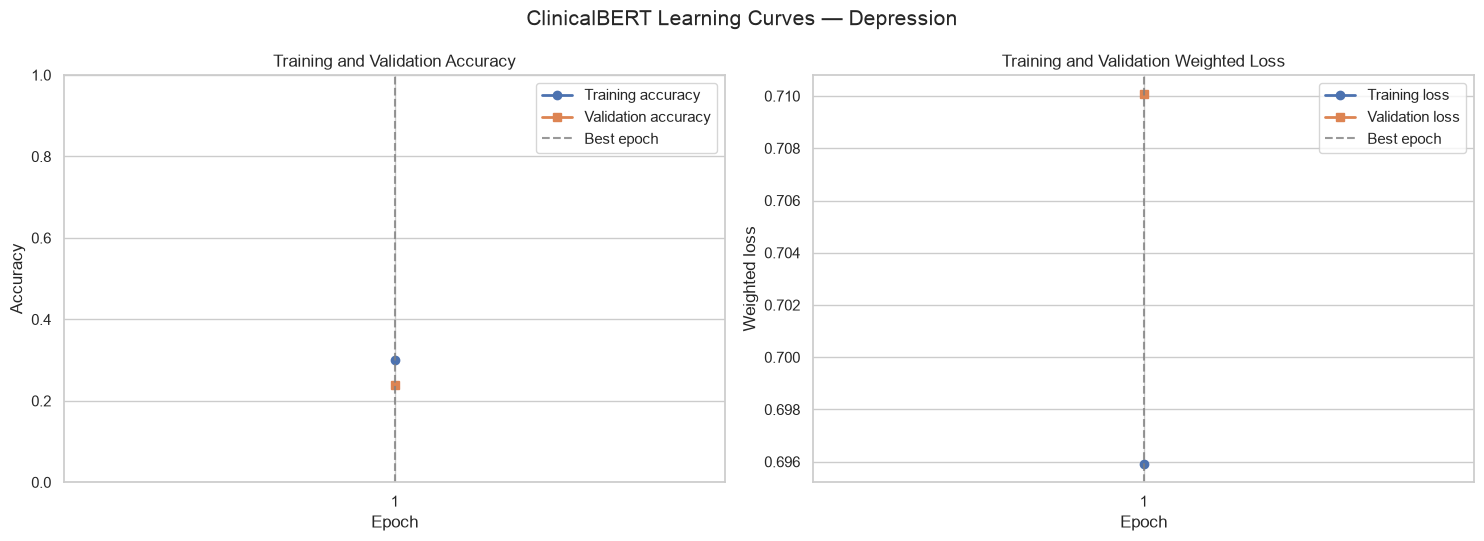

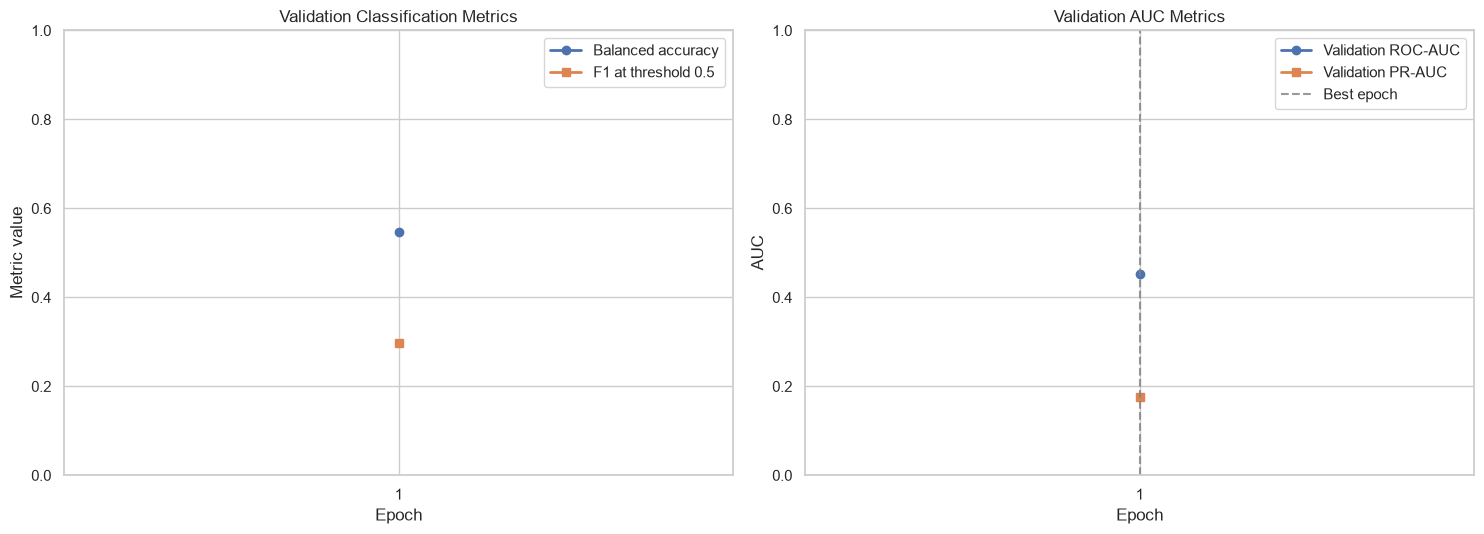

In [29]:
# ============================================================
# CELL 25 - PLOT TRAINING AND VALIDATION HISTORY
# ============================================================

epochs = training_history["epoch"].astype(int)

figure, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5.5))
axes[0].plot(
    epochs,
    training_history["training_accuracy"],
    marker="o",
    linewidth=2,
    label="Training accuracy",
)
axes[0].plot(
    epochs,
    training_history["validation_accuracy"],
    marker="s",
    linewidth=2,
    label="Validation accuracy",
)
axes[0].axvline(best_epoch, color="grey", linestyle="--", alpha=0.8, label="Best epoch")
if early_stop_signal_epoch is not None:
    axes[0].axvline(
        early_stop_signal_epoch, color="red", linestyle=":", alpha=0.8, label="Patience reached"
    )
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].set_xticks(epochs)
axes[0].legend()

axes[1].plot(
    epochs,
    training_history["training_loss"],
    marker="o",
    linewidth=2,
    label="Training loss",
)
axes[1].plot(
    epochs,
    training_history["validation_loss"],
    marker="s",
    linewidth=2,
    label="Validation loss",
)
axes[1].axvline(best_epoch, color="grey", linestyle="--", alpha=0.8, label="Best epoch")
if early_stop_signal_epoch is not None:
    axes[1].axvline(
        early_stop_signal_epoch, color="red", linestyle=":", alpha=0.8, label="Patience reached"
    )
axes[1].set_title("Training and Validation Weighted Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Weighted loss")
axes[1].set_xticks(epochs)
axes[1].legend()

figure.suptitle(f"ClinicalBERT Learning Curves — {TASK_NAME.title()}", fontsize=15)
figure.tight_layout()
accuracy_loss_plot_path = FIGURE_DIR / "training_validation_accuracy_loss.png"
figure.savefig(accuracy_loss_plot_path, dpi=REPORT_FIGURE_DPI, bbox_inches="tight")
plt.show()

figure, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5.5))
axes[0].plot(
    epochs,
    training_history["validation_balanced_accuracy"],
    marker="o",
    linewidth=2,
    label="Balanced accuracy",
)
axes[0].plot(
    epochs,
    training_history["validation_f1_at_0_5"],
    marker="s",
    linewidth=2,
    label="F1 at threshold 0.5",
)
axes[0].set_title("Validation Classification Metrics")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Metric value")
axes[0].set_ylim(0, 1)
axes[0].set_xticks(epochs)
axes[0].legend()

axes[1].plot(
    epochs,
    training_history["validation_roc_auc"],
    marker="o",
    linewidth=2,
    label="Validation ROC-AUC",
)
axes[1].plot(
    epochs,
    training_history["validation_pr_auc"],
    marker="s",
    linewidth=2,
    label="Validation PR-AUC",
)
axes[1].axvline(best_epoch, color="grey", linestyle="--", alpha=0.8, label="Best epoch")
axes[1].set_title("Validation AUC Metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].set_ylim(0, 1)
axes[1].set_xticks(epochs)
axes[1].legend()

figure.tight_layout()
validation_metric_plot_path = FIGURE_DIR / "validation_metrics_by_epoch.png"
figure.savefig(validation_metric_plot_path, dpi=REPORT_FIGURE_DPI, bbox_inches="tight")
plt.show()


## 9. Select the classification threshold on validation data

The best saved checkpoint is reloaded. Validation probabilities are then used to choose the threshold that maximises validation F1. This is a model-selection decision, so it must be completed without looking at test performance.

In [30]:
# ============================================================
# CELL 26 - RELOAD THE BEST VALIDATION CHECKPOINT
# ============================================================

best_model = AutoModelForSequenceClassification.from_pretrained(BEST_MODEL_DIR)
best_model.to(DEVICE)
best_model.eval()
print("Reloaded best checkpoint from:")
print(BEST_MODEL_DIR)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Reloaded best checkpoint from:
/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/clinicalbert_frozen_baseline/clinicalbert_frozen_baseline_depression_masked_selected_smoke/best_model


In [31]:
# ============================================================
# CELL 27 - GENERATE VALIDATION PROBABILITIES
# ============================================================

final_validation_loss, final_validation_labels, final_validation_probabilities = evaluate_model(
    model_object=best_model, data_loader=validation_loader, class_weights=CLASS_WEIGHTS
)
SELECTED_THRESHOLD, selected_validation_f1, validation_threshold_table = select_f1_threshold(
    labels=final_validation_labels, positive_probabilities=(final_validation_probabilities)
)
validation_metrics = calculate_classification_metrics(
    labels=final_validation_labels,
    positive_probabilities=(final_validation_probabilities),
    threshold=SELECTED_THRESHOLD,
)
validation_metrics["weighted_loss"] = float(final_validation_loss)
validation_predictions = split_frames["validation"][
    ["subject_id", "hadm_id", "split", "label", "clinicalbert_token_count", "requires_truncation"]
].copy()
validation_predictions["positive_probability"] = final_validation_probabilities
validation_predictions["predicted_label"] = (
    final_validation_probabilities >= SELECTED_THRESHOLD
).astype(int)
validation_predictions.to_csv(PREDICTION_DIR / "validation_predictions.csv", index=False)
print("Selected validation threshold:", round(SELECTED_THRESHOLD, 6))
print("Validation F1 at selected threshold:", round(selected_validation_f1, 6))
display(pd.DataFrame({"metric": validation_metrics.keys(), "value": validation_metrics.values()}))

Selected validation threshold: 0.536794
Validation F1 at selected threshold: 0.315789


,metric,value
0,threshold,0.536794
1,accuracy,0.480000
2,balanced_accuracy,0.589286
3,precision,0.200000
4,recall,0.750000
5,specificity,0.428571
6,f1,0.315789
7,roc_auc,0.452381
8,pr_auc,0.176812
9,true_negative,9.000000


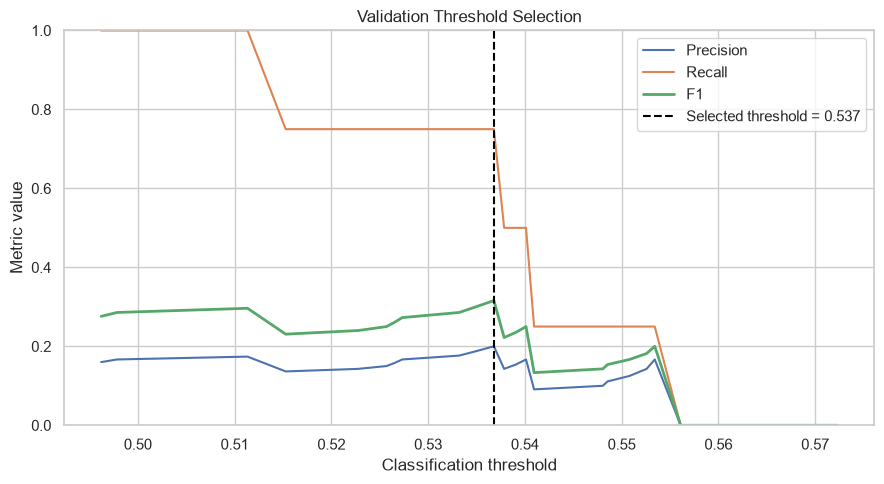

In [32]:
# ============================================================
# CELL 28 - PLOT VALIDATION THRESHOLD SELECTION
# ============================================================

plt.figure(figsize=(9, 5))
plt.plot(
    validation_threshold_table["threshold"],
    validation_threshold_table["precision"],
    label="Precision",
)
plt.plot(
    validation_threshold_table["threshold"], validation_threshold_table["recall"], label="Recall"
)
plt.plot(
    validation_threshold_table["threshold"],
    validation_threshold_table["f1"],
    label="F1",
    linewidth=2,
)
plt.axvline(
    SELECTED_THRESHOLD,
    color="black",
    linestyle="--",
    label=(f"Selected threshold = " f"{SELECTED_THRESHOLD:.3f}"),
)
plt.title("Validation Threshold Selection")
plt.xlabel("Classification threshold")
plt.ylabel("Metric value")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
threshold_plot_path = FIGURE_DIR / "validation_threshold_selection.png"
plt.savefig(threshold_plot_path, dpi=200, bbox_inches="tight")
plt.show()

## 10. Final test-set evaluation

At this point the following decisions are fixed:

- masked dataset;
- `text_selected` input;
- ClinicalBERT checkpoint;
- 512-token truncation;
- class weights;
- selected validation threshold.

The test split is now used for the first and only final evaluation. Do not revise the model, preprocessing, or threshold based on the test results.

In [33]:
# ============================================================
# CELL 29 - EVALUATE THE FROZEN MODEL ON THE TEST SET
# ============================================================

test_metrics = None
test_predictions = None
test_classification_report_table = None
if EVALUATE_TEST_SET:
    # --------------------------------------------------------
    # GENERATE TEST PROBABILITIES
    # --------------------------------------------------------

    test_loss, test_labels, test_probabilities = evaluate_model(
        model_object=best_model,
        data_loader=test_loader,
        class_weights=CLASS_WEIGHTS,
        progress_description="Evaluating test data",
    )
    test_predictions_at_threshold = (test_probabilities >= SELECTED_THRESHOLD).astype(int)

    # --------------------------------------------------------
    # CALCULATE OVERALL TEST METRICS
    # --------------------------------------------------------

    test_metrics = calculate_classification_metrics(
        labels=test_labels, positive_probabilities=test_probabilities, threshold=SELECTED_THRESHOLD
    )
    test_metrics["weighted_loss"] = float(test_loss)
    print("Final test metrics:")
    display(pd.DataFrame({"metric": test_metrics.keys(), "value": test_metrics.values()}).round(6))

    # --------------------------------------------------------
    # CREATE THE SKLEARN CLASSIFICATION REPORT
    # --------------------------------------------------------

    test_classification_report = classification_report(
        test_labels,
        test_predictions_at_threshold,
        labels=[0, 1],
        target_names=[ID_TO_LABEL[0], ID_TO_LABEL[1]],
        output_dict=True,
        zero_division=0,
    )
    test_classification_report_table = pd.DataFrame(test_classification_report).transpose()
    print("\nTest classification report:")
    display(test_classification_report_table.round(4))

    # --------------------------------------------------------
    # SAVE TEST PREDICTIONS AND CLASSIFICATION REPORT
    # --------------------------------------------------------

    test_predictions = split_frames["test"][
        [
            "subject_id",
            "hadm_id",
            "split",
            "label",
            "clinicalbert_token_count",
            "requires_truncation",
        ]
    ].copy()
    test_predictions["positive_probability"] = test_probabilities
    test_predictions["predicted_label"] = test_predictions_at_threshold
    test_predictions.to_csv(PREDICTION_DIR / "test_predictions.csv", index=False)
    test_classification_report_table.to_csv(
        OUTPUT_DIR / "test_classification_report.csv", index=True
    )
else:
    print("Test evaluation was skipped because " "EVALUATE_TEST_SET is False.")

Evaluating test data:   0%|                                | 0/7 [00:00<?, ?batc

Final test metrics:


,metric,value
0,threshold,0.536794
1,accuracy,0.480000
2,balanced_accuracy,0.488095
3,precision,0.153846
4,recall,0.500000
5,specificity,0.476190
6,f1,0.235294
7,roc_auc,0.333333
8,pr_auc,0.156964
9,true_negative,10.000000



Test classification report:


,precision,recall,f1-score,support
no_depression,0.8333,0.4762,0.6061,21.00
depression,0.1538,0.5000,0.2353,4.00
accuracy,0.4800,0.4800,0.4800,0.48
macro avg,0.4936,0.4881,0.4207,25.00
weighted avg,0.7246,0.4800,0.5467,25.00


### Inspect the first 100 test predictions

The table below is the text-classification equivalent of listing image filenames with predicted and actual classes. It uses admission identifiers, class probabilities, the frozen validation-selected threshold, and a correctness flag. The full prediction file is still saved separately.


In [34]:
# ============================================================
# CELL 29A - DISPLAY THE FIRST 100 TEST PREDICTIONS
# ============================================================

if EVALUATE_TEST_SET:
    prediction_display = test_predictions.head(PREDICTION_DISPLAY_COUNT).copy()
    prediction_display["actual_class"] = prediction_display["label"].map(ID_TO_LABEL)
    prediction_display["predicted_class"] = prediction_display["predicted_label"].map(ID_TO_LABEL)
    prediction_display["prediction_confidence"] = np.where(
        prediction_display["predicted_label"].eq(1),
        prediction_display["positive_probability"],
        1 - prediction_display["positive_probability"],
    )
    prediction_display["correct"] = prediction_display["label"].eq(
        prediction_display["predicted_label"]
    )

    prediction_display_columns = [
        "subject_id",
        "hadm_id",
        "actual_class",
        "predicted_class",
        "positive_probability",
        "prediction_confidence",
        "correct",
        "clinicalbert_token_count",
        "requires_truncation",
    ]
    prediction_display_output = prediction_display[prediction_display_columns]
    prediction_display_output.to_csv(
        PREDICTION_DIR / "test_predictions_first_100.csv",
        index=False,
    )

    print(
        f"Displaying {len(prediction_display_output)} of "
        f"{len(test_predictions):,} test predictions:"
    )
    with pd.option_context("display.max_rows", PREDICTION_DISPLAY_COUNT):
        display(
            prediction_display_output.style.format(
                {
                    "positive_probability": "{:.4f}",
                    "prediction_confidence": "{:.4f}",
                }
            )
        )
else:
    print("Prediction display skipped because EVALUATE_TEST_SET is False.")


Displaying 25 of 25 test predictions:


,subject_id,hadm_id,actual_class,predicted_class,positive_probability,prediction_confidence,correct,clinicalbert_token_count,requires_truncation
0,10959084,21423601,depression,depression,0.5417,0.5417,True,1707,True
1,19714588,24420641,no_depression,depression,0.5407,0.5407,False,771,True
2,13605251,27562508,depression,depression,0.5494,0.5494,True,1977,True
3,12115786,23032218,no_depression,depression,0.5593,0.5593,False,648,True
4,10834401,29862362,depression,no_depression,0.5129,0.4871,False,1106,True
5,18874830,22987908,no_depression,depression,0.5609,0.5609,False,1023,True
6,14331232,29674674,depression,no_depression,0.5016,0.4984,False,1587,True
7,11206664,27841571,no_depression,depression,0.5622,0.5622,False,564,True
8,14605415,22846960,no_depression,no_depression,0.5159,0.4841,True,1185,True
9,12501169,27937568,no_depression,depression,0.5408,0.5408,False,925,True


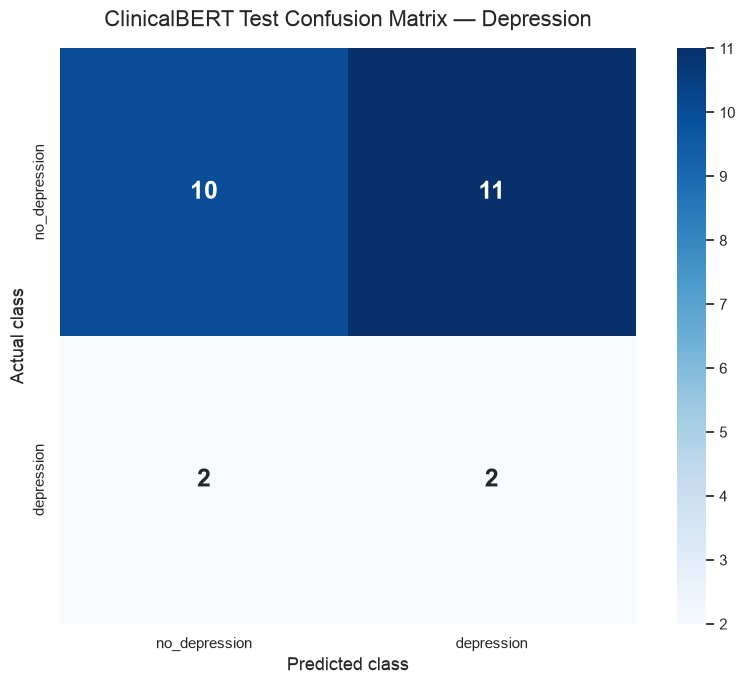

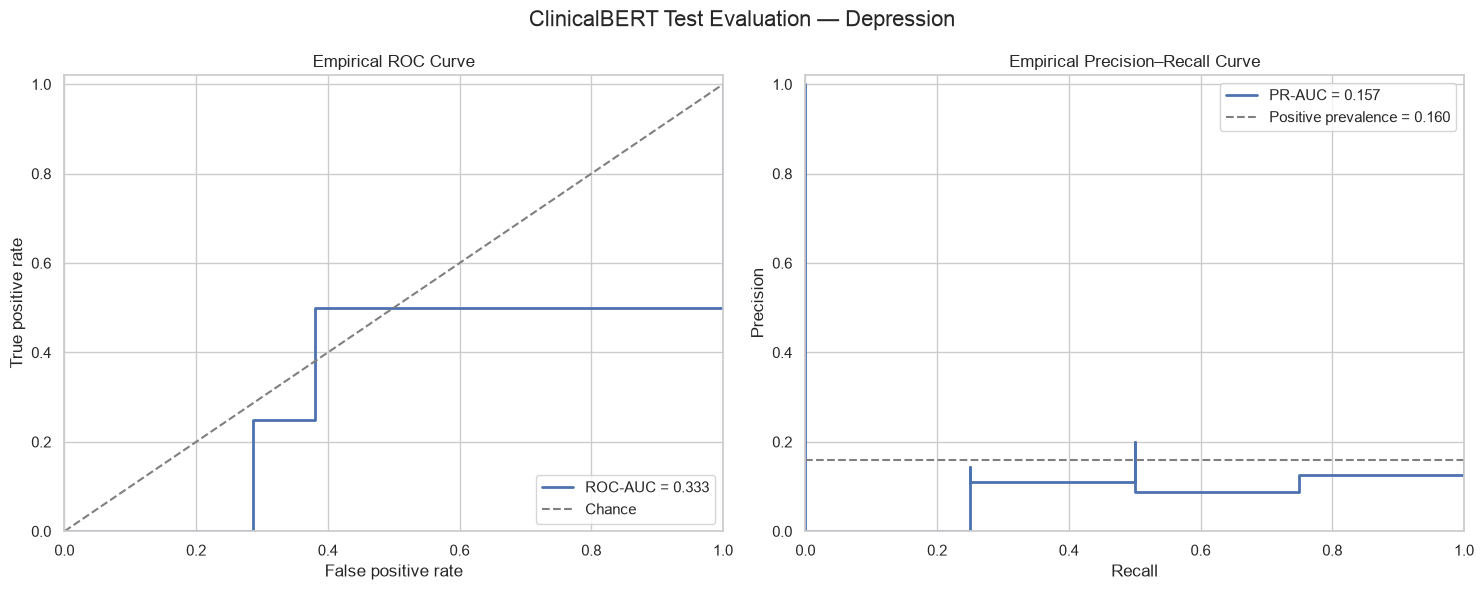

The step shape is statistically correct: each change occurs at an observed probability threshold. A larger full test set normally makes the curves appear denser; artificial smoothing has not been applied.


In [35]:
# ============================================================
# CELL 30 - DISPLAY REPORT-READY CONFUSION MATRIX AND CURVES
# ============================================================

if EVALUATE_TEST_SET:
    test_confusion_matrix = confusion_matrix(
        test_labels,
        test_predictions_at_threshold,
        labels=[0, 1],
    )
    false_positive_rates, true_positive_rates, _ = roc_curve(
        test_labels,
        test_probabilities,
        drop_intermediate=False,
    )
    test_precision_values, test_recall_values, _ = precision_recall_curve(
        test_labels,
        test_probabilities,
    )

    # A large, separate confusion matrix is easier to use in the report.
    figure, axis = plt.subplots(figsize=(9, 7))
    sns.heatmap(
        test_confusion_matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=True,
        square=True,
        annot_kws={"size": 18, "weight": "bold"},
        xticklabels=[ID_TO_LABEL[0], ID_TO_LABEL[1]],
        yticklabels=[ID_TO_LABEL[0], ID_TO_LABEL[1]],
        ax=axis,
    )
    axis.set_title(
        f"ClinicalBERT Test Confusion Matrix — {TASK_NAME.title()}",
        fontsize=16,
        pad=16,
    )
    axis.set_xlabel("Predicted class", fontsize=13)
    axis.set_ylabel("Actual class", fontsize=13)
    axis.tick_params(axis="both", labelsize=11)
    figure.tight_layout()
    confusion_matrix_plot_path = FIGURE_DIR / "test_confusion_matrix.png"
    figure.savefig(
        confusion_matrix_plot_path,
        dpi=REPORT_FIGURE_DPI,
        bbox_inches="tight",
    )
    plt.show()

    # ROC and PR curves are empirical threshold curves. Their stair-step
    # appearance is expected, especially for a 200-record smoke test.
    figure, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
    axes[0].step(
        false_positive_rates,
        true_positive_rates,
        where="post",
        linewidth=2,
        label=f"ROC-AUC = {test_metrics['roc_auc']:.3f}",
    )
    axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
    axes[0].set_title("Empirical ROC Curve")
    axes[0].set_xlabel("False positive rate")
    axes[0].set_ylabel("True positive rate")
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(0, 1.02)
    axes[0].legend(loc="lower right")

    positive_prevalence = float(np.mean(test_labels))
    axes[1].step(
        test_recall_values[::-1],
        test_precision_values[::-1],
        where="post",
        linewidth=2,
        label=f"PR-AUC = {test_metrics['pr_auc']:.3f}",
    )
    axes[1].axhline(
        positive_prevalence,
        linestyle="--",
        color="grey",
        label=f"Positive prevalence = {positive_prevalence:.3f}",
    )
    axes[1].set_title("Empirical Precision–Recall Curve")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_xlim(0, 1)
    axes[1].set_ylim(0, 1.02)
    axes[1].legend(loc="best")

    figure.suptitle(
        f"ClinicalBERT Test Evaluation — {TASK_NAME.title()}",
        fontsize=16,
    )
    figure.tight_layout()
    roc_pr_plot_path = FIGURE_DIR / "test_roc_pr_curves.png"
    figure.savefig(roc_pr_plot_path, dpi=REPORT_FIGURE_DPI, bbox_inches="tight")
    plt.show()

    print(
        "The step shape is statistically correct: each change occurs at an "
        "observed probability threshold. A larger full test set normally makes "
        "the curves appear denser; artificial smoothing has not been applied."
    )


## 11. Save a Flask-ready deployment bundle

The recommended portable format for this project is a Hugging Face directory saved with `safetensors`, together with the matching tokenizer and a JSON inference contract. Flask should load this bundle once when the API starts; the React/MERN frontend should call the Flask endpoint rather than loading the model in the browser.

The model was trained on masked `text_selected`. Therefore, production input must pass through the same section-selection, cleaning and masking rules before prediction. The saved inference class assumes that this matching preprocessing has already occurred.


In [36]:
# ============================================================
# CELL 31 - SAVE A FLASK-READY DEPLOYMENT BUNDLE
# ============================================================

best_model.save_pretrained(
    DEPLOYMENT_MODEL_DIR,
    safe_serialization=True,
)
tokenizer.save_pretrained(DEPLOYMENT_MODEL_DIR)

deployment_configuration = {
    "task": TASK_NAME,
    "model_name": MODEL_NAME,
    "training_strategy": TRAINING_STRATEGY,
    "encoder_frozen_during_training": True,
    "model_subdirectory": "model",
    "positive_label": ID_TO_LABEL[1],
    "negative_label": ID_TO_LABEL[0],
    "positive_label_id": 1,
    "negative_label_id": 0,
    "classification_threshold": float(SELECTED_THRESHOLD),
    "maximum_length": MAX_LENGTH,
    "training_text_column": TEXT_COLUMN,
    "expects_masked_text": True,
    "expects_selected_sections": True,
    "input_contract": (
        "Apply the same Notebook 03 cleaning, clinical-section selection and masking "
        "before calling the model."
    ),
}

with open(
    DEPLOYMENT_BUNDLE_DIR / "inference_config.json",
    "w",
    encoding="utf-8",
) as configuration_file:
    json.dump(deployment_configuration, configuration_file, indent=2)

deployment_loader_source = r'''from pathlib import Path
import json

import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer


class ClinicalBERTPredictor:
    """Load once when Flask starts and reuse for every request."""

    def __init__(self, bundle_directory, device=None):
        self.bundle_directory = Path(bundle_directory)
        with open(
            self.bundle_directory / "inference_config.json",
            "r",
            encoding="utf-8",
        ) as configuration_file:
            self.configuration = json.load(configuration_file)

        model_directory = self.bundle_directory / self.configuration["model_subdirectory"]
        self.device = torch.device(
            device or ("cuda" if torch.cuda.is_available() else "cpu")
        )
        self.tokenizer = AutoTokenizer.from_pretrained(model_directory)
        self.model = AutoModelForSequenceClassification.from_pretrained(model_directory)
        self.model.to(self.device)
        self.model.eval()

    @torch.inference_mode()
    def predict(self, preprocessed_texts):
        if isinstance(preprocessed_texts, str):
            preprocessed_texts = [preprocessed_texts]

        encoded = self.tokenizer(
            list(preprocessed_texts),
            truncation=True,
            max_length=self.configuration["maximum_length"],
            padding=True,
            return_tensors="pt",
        )
        encoded = {name: value.to(self.device) for name, value in encoded.items()}
        logits = self.model(**encoded).logits
        positive_probabilities = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
        threshold = self.configuration["classification_threshold"]

        return [
            {
                "positive_probability": float(probability),
                "predicted_label_id": int(probability >= threshold),
                "predicted_label": (
                    self.configuration["positive_label"]
                    if probability >= threshold
                    else self.configuration["negative_label"]
                ),
                "threshold": float(threshold),
            }
            for probability in positive_probabilities
        ]
'''

(DEPLOYMENT_BUNDLE_DIR / "clinicalbert_inference.py").write_text(
    deployment_loader_source,
    encoding="utf-8",
)

deployment_readme = f"""ClinicalBERT frozen-encoder baseline deployment bundle
=========================================================

Task: {TASK_NAME}
Model: {MODEL_NAME}
Training strategy: {TRAINING_STRATEGY}
Threshold: {SELECTED_THRESHOLD:.8f}
Maximum input length: {MAX_LENGTH} tokens

The model expects text processed exactly like Notebook 03:
- selected clinical sections
- cleaned text
- masked explicit depression/anxiety terms

Flask usage:
    from clinicalbert_inference import ClinicalBERTPredictor
    predictor = ClinicalBERTPredictor('/path/to/deployment_bundle')
    result = predictor.predict(preprocessed_text)

Load ClinicalBERTPredictor once when the Flask application starts.
Do not reload the model for every HTTP request.
"""
(DEPLOYMENT_BUNDLE_DIR / "README.txt").write_text(
    deployment_readme,
    encoding="utf-8",
)

print("Flask-ready deployment bundle saved to:")
print(DEPLOYMENT_BUNDLE_DIR)
print("\nBundle contents:")
for bundle_path in sorted(DEPLOYMENT_BUNDLE_DIR.rglob("*")):
    if bundle_path.is_file():
        print("-", bundle_path.relative_to(DEPLOYMENT_BUNDLE_DIR))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Flask-ready deployment bundle saved to:
/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/clinicalbert_frozen_baseline/clinicalbert_frozen_baseline_depression_masked_selected_smoke/deployment_bundle

Bundle contents:
- README.txt
- clinicalbert_inference.py
- inference_config.json
- model/config.json
- model/model.safetensors
- model/tokenizer.json
- model/tokenizer_config.json


## 12. Save the run metadata and outputs

The final cells save enough information to reproduce and audit the experiment:

- best model and tokenizer;
- training history;
- exact token-length and truncation summary;
- validation predictions and selected threshold;
- test predictions and metrics;
- run configuration and package versions.

In [37]:
# ============================================================
# CELL 31 - SAVE METRICS AND RUN MANIFEST
# ============================================================

def convert_to_json_value(value):
    if isinstance(value, (np.integer, np.floating)):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    raise TypeError(f"Cannot serialise value of type " f"{type(value).__name__}.")

metrics_output = {"validation": validation_metrics, "test": test_metrics}
run_manifest = {
    "run_name": RUN_NAME,
    "task": TASK_NAME,
    "dataset_path": str(DATASET_PATH),
    "dataset_is_masked": True,
    "text_column": TEXT_COLUMN,
    "model_name": MODEL_NAME,
    "training_strategy": TRAINING_STRATEGY,
    "encoder_frozen_during_training": True,
    "total_parameters": total_parameter_count,
    "trainable_parameters": trainable_parameter_count,
    "frozen_parameters": frozen_parameter_count,
    "maximum_length": MAX_LENGTH,
    "input_strategy": ("single selected note with truncation; no chunking"),
    "seed": SEED,
    "smoke_test": SMOKE_TEST,
    "split_rows": {split_name: len(split_frames[split_name]) for split_name in SPLIT_ORDER},
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "epochs_requested": NUMBER_OF_EPOCHS,
    "last_completed_epoch": last_completed_epoch,
    "stop_training_when_patience_reached": STOP_TRAINING_WHEN_PATIENCE_REACHED,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_minimum_improvement": EARLY_STOPPING_MINIMUM_IMPROVEMENT,
    "early_stop_signal_epoch": early_stop_signal_epoch,
    "training_batch_size": TRAIN_BATCH_SIZE,
    "evaluation_batch_size": EVALUATION_BATCH_SIZE,
    "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "frozen_baseline_verified": FROZEN_BASELINE_VERIFIED,
    "best_model_directory": str(BEST_MODEL_DIR),
    "early_stop_signal_model_directory": str(EARLY_STOP_SIGNAL_MODEL_DIR),
    "final_epoch_model_directory": str(FINAL_EPOCH_MODEL_DIR),
    "best_epoch": best_epoch,
    "best_validation_pr_auc": (best_validation_pr_auc),
    "selected_validation_threshold": SELECTED_THRESHOLD,
    "deployment_bundle": str(DEPLOYMENT_BUNDLE_DIR),
    "class_weights": (class_weight_values.tolist()),
    "token_length_summary": (token_length_summary.to_dict(orient="records")),
    "package_versions": {
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "datasets": hf_datasets.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
    "device": str(DEVICE),
    "total_training_seconds": (total_training_seconds),
}
with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as metrics_file:
    json.dump(metrics_output, metrics_file, indent=2, default=convert_to_json_value)

with open(OUTPUT_DIR / "run_manifest.json", "w", encoding="utf-8") as manifest_file:
    json.dump(run_manifest, manifest_file, indent=2, default=convert_to_json_value)

token_length_summary.to_csv(OUTPUT_DIR / "token_length_summary.csv", index=False)
working_split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)
print("Run outputs saved to:")
print(OUTPUT_DIR)

Run outputs saved to:
/Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/clinicalbert_frozen_baseline/clinicalbert_frozen_baseline_depression_masked_selected_smoke


In [38]:
# ============================================================
# CELL 32 - DISPLAY THE FINAL OUTPUT SUMMARY
# ============================================================

output_files = sorted(path for path in OUTPUT_DIR.rglob("*") if path.is_file())
output_file_table = pd.DataFrame(
    {
        "file": [str(path.relative_to(OUTPUT_DIR)) for path in output_files],
        "size_mb": [round(path.stat().st_size / 1_048_576, 3) for path in output_files],
    }
)
display(output_file_table)
final_summary = pd.DataFrame(
    {
        "item": [
            "Task",
            "Run mode",
            "Masked dataset",
            "Input text",
            "Training strategy",
            "Trainable parameters",
            "Frozen parameters",
            "Frozen-baseline verified",
            "Best epoch",
            "Early-stop signal epoch",
            "Last completed epoch",
            "Training batch size",
            "Effective batch size",
            "Best validation PR-AUC",
            "Selected validation threshold",
            "Test F1",
            "Test PR-AUC",
            "Test ROC-AUC",
            "Deployment bundle",
        ],
        "value": [
            TASK_NAME,
            RUN_MODE,
            DATASET_PATH.name,
            TEXT_COLUMN,
            TRAINING_STRATEGY,
            trainable_parameter_count,
            frozen_parameter_count,
            FROZEN_BASELINE_VERIFIED,
            best_epoch,
            early_stop_signal_epoch,
            last_completed_epoch,
            TRAIN_BATCH_SIZE,
            TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS,
            best_validation_pr_auc,
            SELECTED_THRESHOLD,
            (test_metrics["f1"] if test_metrics is not None else "Not evaluated"),
            (test_metrics["pr_auc"] if test_metrics is not None else "Not evaluated"),
            (test_metrics["roc_auc"] if test_metrics is not None else "Not evaluated"),
            str(DEPLOYMENT_BUNDLE_DIR),
        ],
    }
)
display(final_summary)

,file,size_mb
0,best_model/config.json,0.001
1,best_model/model.safetensors,413.199
2,best_model/tokenizer.json,0.638
3,best_model/tokenizer_config.json,0.000
4,deployment_bundle/README.txt,0.001
5,deployment_bundle/clinicalbert_inference.py,0.002
6,deployment_bundle/inference_config.json,0.001
7,deployment_bundle/model/config.json,0.001
8,deployment_bundle/model/model.safetensors,413.199
9,deployment_bundle/model/tokenizer.json,0.638


,item,value
0,Task,depression
1,Run mode,smoke
2,Masked dataset,depression_dataset_masked.parquet
3,Input text,text_selected
4,Training strategy,frozen_encoder_classifier_only
5,Trainable parameters,1538
6,Frozen parameters,108310272
7,Frozen-baseline verified,True
8,Best epoch,1
9,Early-stop signal epoch,None


## 13. Recommended execution order

1. Set `SMOKE_TEST = True` and run the depression notebook from top to bottom.
2. Confirm that the model summary reports only the classification head as trainable.
3. Confirm that the smoke-test parameter audit reports the encoder as unchanged and the classification head as changed.
4. Resolve any pipeline or memory issues without using full test results for model decisions.
5. Freeze the experimental settings and set `SMOKE_TEST = False`.
6. Run the full depression frozen-encoder baseline from a restarted kernel.
7. Record the saved metrics, plots, truncation rates, package versions, and run manifest.
8. Compare this run with the fully fine-tuned ClinicalBERT depression run using the same split and evaluation protocol.

## Interpretation boundary

This notebook is a frozen-feature ClinicalBERT baseline, not a zero-shot model. The pretrained encoder is not updated, but the randomly initialised classification head is trained so the model can produce a meaningful task prediction. Any performance difference from the fully fine-tuned notebook therefore measures the value of adapting the pretrained ClinicalBERT representations to the depression task.
